# EMT Madrid bus electrification: Madrid line and depot model (consolidated)
**IE Sustainability Datathon, October 2026 (Kearney).** This notebook builds the Madrid model: timetable, daily km, buses, energy, charging strategy and depot allocation.

**How to read it.** Every section starts with a short text cell (what and why), then code, then a visible printed check. Provenance labels follow the brief: **V** verified from a cited source, **D** derived transparently from source data, **P** proxy from indirect evidence, **A** explicit assumption. The assumptions register near the end collects them.

**Three time points are combined, on purpose** (all documented below):
1. Fleet baseline: **31 Dec 2025** (fleet history, reconciled with published figures).
2. `peak_buses`: EMT supply data, **proxy day 2026-05-12** (the supply file ends on 2026-08-31 and the GTFS feed starts on 2026-11-06, so no date exists in both).
3. Timetable and km: GTFS **reference day 2026-11-17** (Tuesday).

**Contents:** 1 Setup, 2 Load data, 3 Reference date, 4 Supply data and proxy day, 5 Fleet baseline, 6 Line ID mapping, 7 Daily km, 8 File 2 core, 9 Sensitivities, 10 Depot allocation, 11 Assumptions register, 12 Regression checks, 13 Next steps.

## 1. Setup
All dates and switches are defined once here. The mandatory parameters come from Section 4.5 of the brief. Two choices are team assumptions (class A): the Opportunity-charging limit and the minimum line size used by the articulated-bus proxy.

In [1]:
import os, glob, zipfile, warnings
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 110)

# ---- analysis dates: defined once, reused everywhere ----
REFERENCE_DATE    = '2026-11-17'   # GTFS reference day (Tuesday); the same date goes into File 1 and File 2
SUPPLY_PROXY_DATE = '2026-05-12'   # proxy day for peak_buses (supply data ends 2026-08-31)
SUPPLY_SENS_DATES = {'high': '2026-05-19', 'low': '2026-06-17'}   # sensitivity days
BASELINE_DATE     = '2025-12-31'   # fleet baseline (File 1, File 4)
ALLOC_CASE        = 'A'            # depot allocation: 'A' = end state with La Elipa reopened (base, files 2 and 3), 'B' = interim while La Elipa is closed (until mid-2029)

ref = pd.Timestamp(REFERENCE_DATE)

# ---- fixed parameters from the brief (Section 4.5) ----
FIXED = dict(kwh_std=1.30, kwh_art=1.85, range_std=300, range_art=240,
             charger_kw=100, window_h=7, eff=0.90,
             cng_kg_km_std=0.45, cng_kg_km_art=0.65,
             bus_price_std=615_000, bus_price_art=800_000, annual_days=365)
KWH   = {'Standard': FIXED['kwh_std'],   'Articulated': FIXED['kwh_art']}
LIMIT = {'Standard': FIXED['range_std'], 'Articulated': FIXED['range_art']}

# ---- team assumptions (class A) ----
OPP_MAX = 2.0          # Opportunity charging is accepted up to 2.0 x the effective daily range
MIN_BUSES_ART = 5      # articulated-bus proxy only considers lines with at least this many peak buses

# ---- emission factors (sources and caveats in Section 10b; verify before the final run) ----
CNG_CO2_KG_PER_KWH_PCS = 0.182   # MITECO, natural gas, kg CO2 per kWh of higher heating value (PCS)
CNG_PCS_KWH_PER_KG     = 14.8    # assumption (A): higher heating value of CNG, kWh per kg
ELEC_TOTAL_MT_CO2EQ    = 29.5    # Red Eléctrica, Informe del Sistema Eléctrico 2025, national generation, Mt CO2 eq
ELEC_GENERATION_TWH    = 272.05  # derived (D): 150,988 GWh renewable / 55.5% share; check against REE REData
# ---- S1 sequencing assumptions (class A) ----
W_IMPACT = 0.5                   # weight of CO2 avoided in the priority score; the rest is range headroom
S1_RAMP = {2026: 0.05, 2027: 0.30, 2028: 0.54, 2029: 0.78, 2030: 1.00}   # cumulative share of peak buses electrified by year end
# ---- File 3 assumptions (class A) ----
CONN_SCENARIO = 'base'                                   # 'low' | 'base' | 'high' multiplier on the estimated connection MW
CONN_FACTORS = {'low': 0.5, 'base': 1.0, 'high': 1.5}
EVIDENCED_CONN_MW = {'Carabanchel': 10.0, 'La Elipa': 20.0, 'Sanchinarro': 8.0}                # documented: two transformation centres, 10 MVA combined (treated as MW, power factor 1)
EMPTY_DEPOT_YEAR = 2030                                  # conversion_year for a depot with no assigned lines (open question for a mentor)

# Public holidays near the reference date, as entered by the team (verify against the official calendar)
MADRID_HOLIDAYS = {pd.Timestamp(d) for d in ['2026-11-09', '2026-12-07', '2026-12-08', '2026-12-25']}

print('Reference date  :', ref.date(), ref.day_name())
print('Supply proxy day:', SUPPLY_PROXY_DATE, '| sensitivity days:', SUPPLY_SENS_DATES)
print('Fleet baseline  :', BASELINE_DATE, '| depot allocation case:', ALLOC_CASE)
assert ref.day_name() in ('Tuesday', 'Wednesday'), 'reference day must be a Tuesday or Wednesday'
assert ref not in MADRID_HOLIDAYS, 'reference day is a public holiday'

Reference date  : 2026-11-17 Tuesday
Supply proxy day: 2026-05-12 | sensitivity days: {'high': '2026-05-19', 'low': '2026-06-17'}
Fleet baseline  : 2025-12-31 | depot allocation case: A


## 2. Load the data
The files were downloaded from the public EMT / Madrid Open Data portals on **2026-11-10** (file timestamps). **TODO before submission:** add the landing-page URL of each dataset in the source table of the report annex (the links are listed in Section 4.1 of the brief).

Files are located by name pattern, so differences in spacing do not matter. The GTFS zip is extracted next to the notebook. The reader below tries the usual separators and encodings and prints which one worked, so the load is reproducible.

In [2]:
DATA_DIR = os.getcwd()

def find(pattern):
    hits = [p for p in glob.glob(os.path.join(DATA_DIR, '**', pattern), recursive=True) if os.path.isfile(p)]
    assert len(hits) == 1, f'{pattern}: found {[os.path.relpath(h, DATA_DIR) for h in hits]}'
    return hits[0]

gtfs_zip    = find('GTFS.zip')
supply_path = find('Bus Supply*Offer*2026.csv')
fleet_path  = find('Bus fleet history.csv')
lines_path  = find('2026 LINES.csv')
hist_path   = find('Historical lines.csv')
stops_path  = find('All bus stops.csv')

for name, p in [('GTFS', gtfs_zip), ('Supply', supply_path), ('Fleet history', fleet_path),
                ('2026 passengers', lines_path), ('Historical lines', hist_path), ('Stops', stops_path)]:
    print(f'{name:16s} {os.path.relpath(p, DATA_DIR)}  ({os.path.getsize(p)/1e6:.1f} MB)')

GTFS             GTFS.zip  (21.2 MB)
Supply           Bus Supply  Bus Offer 2026.csv  (21.6 MB)
Fleet history    Bus fleet history.csv  (1.1 MB)
2026 passengers  2026 LINES.csv  (24.4 MB)
Historical lines Historical lines.csv  (0.1 MB)
Stops            All bus stops.csv  (2.7 MB)


In [3]:
# ---- GTFS: all tables loaded as text to keep IDs exactly (leading zeros, letters) ----
gtfs_dir = os.path.join(DATA_DIR, '_gtfs_extracted')
with zipfile.ZipFile(gtfs_zip) as z:
    print('Files in the GTFS zip:', z.namelist())
    z.extractall(gtfs_dir)

gtfs = {f[:-4]: pd.read_csv(os.path.join(gtfs_dir, f), dtype=str)
        for f in sorted(os.listdir(gtfs_dir)) if f.endswith('.txt')}
for name, df in gtfs.items():
    print(f'{name:16s} rows={len(df):>9,}  cols={list(df.columns)}')

# ---- other Madrid files ----
def read_any(path):
    errors = []
    for enc in ['utf-8', 'utf-8-sig', 'latin-1']:
        for sep in [';', ',', '\t', '|']:
            try:
                df = pd.read_csv(path, sep=sep, encoding=enc, low_memory=False)
                if df.shape[1] > 1:
                    print(f'  {os.path.basename(path)} -> encoding={enc!r}, sep={sep!r}')
                    return df
            except Exception as e:
                errors.append(f'{enc}/{sep!r}: {type(e).__name__}')
    raise ValueError(f'Could not read {os.path.basename(path)}. Tried: {errors[:6]}')

supply     = read_any(supply_path)    # EMT buses available per day, line and time band
fleet      = read_any(fleet_path)     # EMT bus fleet history
lines26    = read_any(lines_path)     # passengers per line, date and hour band (used only for the bus-type proxy)
lines_hist = read_any(hist_path)      # historical line records, with a depot code
stops      = read_any(stops_path)     # stops per line and direction, with UTM coordinates

Files in the GTFS zip: ['routes.txt', 'stops.txt', 'trips.txt', 'frequencies.txt', 'calendar_dates.txt', 'calendar.txt', 'agency.txt', 'stop_times.txt', 'shapes.txt']
agency           rows=        1  cols=['agency_id', 'agency_name', 'agency_url', 'agency_timezone', 'agency_lang', 'agency_phone']
calendar         rows=        5  cols=['service_id', 'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday', 'start_date', 'end_date']
calendar_dates   rows=       13  cols=['service_id', 'date', 'exception_type']
frequencies      rows=   87,774  cols=['trip_id', 'start_time', 'end_time', 'headway_secs']
routes           rows=      239  cols=['route_id', 'agency_id', 'route_short_name', 'route_long_name', 'route_desc', 'route_type', 'route_url', 'route_color', 'route_text_color']
shapes           rows=  196,103  cols=['shape_id', 'shape_pt_lat', 'shape_pt_lon', 'shape_pt_sequence', 'shape_dist_traveled']
stop_times       rows=2,244,607  cols=['trip_id', 'arrival_time', 'd

In [4]:
# ---- quick look at every table: shape, columns, first rows ----
for name, df in {'supply': supply, 'fleet': fleet, 'lines26': lines26, 'lines_hist': lines_hist, 'stops': stops}.items():
    print(f'\n=== {name}: shape={df.shape} | columns={list(df.columns)}')
    display(df.head(3))


=== supply: shape=(939717, 5) | columns=['Linea', 'FechaSer', 'TipoDiaMo', 'CodFranja', 'NumCCReal']


,Linea,FechaSer,TipoDiaMo,CodFranja,NumCCReal
0,1,2026-01-01,FE,7,2
1,1,2026-01-01,FE,8,3
2,1,2026-01-01,FE,9,3



=== fleet: shape=(12920, 11) | columns=['vehicleId', 'dateIni', 'dateEnd', 'trade', 'model', 'version', 'typeCapacity', 'fuelType', 'accesibility', 'capacity', 'colour']


,vehicleId,dateIni,dateEnd,trade,model,version,typeCapacity,fuelType,accesibility,capacity,colour
0,51,2023-04-11 00:00:00,9999-12-31 00:00:00,IRIZAR,IETRAM,0,1,EL,4,80,B
1,52,2023-03-25 00:00:00,9999-12-31 00:00:00,IRIZAR,IETRAM,0,1,EL,4,80,B
2,53,2023-05-05 00:00:00,9999-12-31 00:00:00,IRIZAR,IETRAM,0,1,EL,4,80,B



=== lines26: shape=(1026041, 4) | columns=['Fecha', 'Linea', 'Franja', 'TotalViajeros']


,Fecha,Linea,Franja,TotalViajeros
0,2026-01-01,1,H07,17
1,2026-01-01,1,H08,21
2,2026-01-01,1,H09,26



=== lines_hist: shape=(430, 10) | columns=['line', 'grpLin', 'dateIni', 'dateEnd', 'depo', 'label', 'nameTo', 'nameFrom', 'externalTo', 'externalFrom']


,line,grpLin,dateIni,dateEnd,depo,label,nameTo,nameFrom,externalTo,externalFrom
0,1,110,2018-11-21 00:00:00,2019-02-19 23:59:59,62825,1,PLAZA DE CRISTO REY,PROSPERIDAD,CRISTO REY,PROSPERIDAD
1,2,110,2018-11-21 00:00:00,2019-02-28 23:59:59,62845,2,PLAZA DE MANUEL BECERRA,AVENIDA REINA VICTORIA,MANUEL BECERRA,REINA VICTORIA
2,3,110,2018-06-13 00:00:00,2019-02-28 23:59:59,62825,3,PUERTA DE TOLEDO,PLAZA DE SAN AMARO,PUERTA TOLEDO,SAN AMARO



=== stops: shape=(12610, 14) | columns=['line', 'dateIni', 'dateEnd', 'label', 'nameTo', 'nameFrom', 'parada', 'secuencia', 'sentido', 'distancia', 'descparada', 'descpostal', 'posX', 'posY']


,line,dateIni,dateEnd,label,nameTo,nameFrom,parada,secuencia,sentido,distancia,descparada,descpostal,posX,posY
0,1,2026-10-31,2999-12-31 23:59:59,1,PLAZA DE CRISTO REY,PROSPERIDAD,4514,1,1,0,Cristo Rey,"Isaac Peral, frente al Nº 40.",439221.0,4476870.0
1,1,2026-10-31,2999-12-31 23:59:59,1,PLAZA DE CRISTO REY,PROSPERIDAD,4022,2,1,295,Isaac Peral-Fernández de los Ríos,Isaac Peral frente al Nº 8,439177.0,4476578.0
2,1,2026-10-31,2999-12-31 23:59:59,1,PLAZA DE CRISTO REY,PROSPERIDAD,3687,3,1,485,Moncloa,Arcipreste de Hita con C/ Fernando el Catolico,439204.0,4476389.0


## 3. Reference date: is it valid in the GTFS feed?
The reference day must be a Tuesday or Wednesday, a working day outside holiday periods, and inside the validity window of the feed. GTFS defines service in two layers: the weekly pattern in `calendar.txt`, and date exceptions in `calendar_dates.txt` (type 1 = added, type 2 = removed). Both are applied.

The feed starts on 2026-11-06, which is why an October date could not be used (it returned 0 trips). The check below compares the reference day with nearby valid weekdays: a similar number of trips means the day is representative. **Strikes and disruptions cannot be verified for a future date: re-check the news once the day has passed** (class A).

In [5]:
cal = gtfs['calendar'].copy()
for c in ['start_date', 'end_date']:
    cal[c] = pd.to_datetime(cal[c], format='%Y%m%d')
cd = gtfs['calendar_dates'].copy()
cd['date'] = pd.to_datetime(cd['date'], format='%Y%m%d')

print('feed_info.txt present:', 'feed_info' in gtfs)
print('calendar.txt range      :', cal.start_date.min().date(), '->', cal.end_date.max().date())
print('calendar_dates.txt range:', cd.date.min().date(), '->', cd.date.max().date())
assert cal.start_date.min() <= ref <= cal.end_date.max(), 'reference day outside the feed validity window'

def active_services(d):
    d = pd.Timestamp(d); dw = d.day_name().lower()
    s = set(cal[(cal[dw] == '1') & (cal.start_date <= d) & (cal.end_date >= d)].service_id)
    e = cd[cd.date == d]
    s |= set(e.loc[e.exception_type == '1', 'service_id'])
    s -= set(e.loc[e.exception_type == '2', 'service_id'])
    return s

trips, routes = gtfs['trips'], gtfs['routes']
active = active_services(ref)
t_ref = trips[trips.service_id.isin(active)].copy()

print('\nRoute types in routes.txt:', routes.route_type.value_counts().to_dict())
print('Active services on the reference date:', len(active), '| exceptions on that date:', int((cd.date == ref).sum()))
print('Trips on the reference date:', len(t_ref), '| lines with at least one trip:', t_ref.route_id.nunique())

print('\nComparison with nearby weekdays (a similar number of trips means a representative day):')
for d in ['2026-11-10', '2026-11-11', REFERENCE_DATE, '2026-11-18', '2026-11-24', '2026-11-25']:
    n = trips.service_id.isin(active_services(d)).sum()
    print(' ', d, pd.Timestamp(d).day_name()[:3], '-> trips:', n)

feed_info.txt present: False
calendar.txt range      : 2026-11-06 -> 2027-12-31
calendar_dates.txt range: 2026-11-07 -> 2026-12-25

Route types in routes.txt: {'3': 239}
Active services on the reference date: 2 | exceptions on that date: 0
Trips on the reference date: 38396 | lines with at least one trip: 234

Comparison with nearby weekdays (a similar number of trips means a representative day):
  2026-11-10 Tue -> trips: 38396
  2026-11-11 Wed -> trips: 38396
  2026-11-17 Tue -> trips: 38396
  2026-11-18 Wed -> trips: 38396
  2026-11-24 Tue -> trips: 38396
  2026-11-25 Wed -> trips: 38396


## 4. Supply data and the proxy day for `peak_buses`
`peak_buses` is the maximum number of buses allocated to a line across the time bands of a day. It must come from the official EMT supply data (using anything else is a disqualification criterion in the brief).

The supply file covers 2026-01-01 to 2026-08-31 and does not contain the reference date, so the brief's rule applies: use the closest equivalent weekday and document it. "Equivalent" is defined here as a regular working-day Tuesday or Wednesday (`TipoDiaMo` = `LA`), not next to a holiday, and **before the summer timetable** (the network's total peak buses falls from mid-June). The table shows the candidates; the chosen day sits at the typical level of April to early June. Two alternative days (high and low) are used for the sensitivity test in Section 9.

In [6]:
supply['date'] = pd.to_datetime(supply['FechaSer'])
print('Supply range:', supply.date.min().date(), '->', supply.date.max().date(),
      '| rows on the reference date:', int((supply.date == ref).sum()))
print('Day types:', sorted(supply.TipoDiaMo.unique()), '(LA = working day, SA = Saturday, FE = Sunday/holiday)')
print('Duplicate (date, line, band) rows:', int(supply.duplicated(['date', 'Linea', 'CodFranja']).sum()))

peak_day = supply.groupby(['date', 'Linea']).NumCCReal.max().rename('peak').reset_index()
daily_sup = peak_day.groupby('date').agg(lines=('Linea', 'nunique'), sum_peaks=('peak', 'sum')).reset_index()
daytype = supply.groupby('date').TipoDiaMo.first()
daily_sup['daytype'] = daily_sup.date.map(daytype)
daily_sup['dow'] = daily_sup.date.dt.day_name()
daily_sup['near_FE'] = ((daily_sup.date - pd.Timedelta(days=1)).map(daytype).eq('FE') |
                        (daily_sup.date + pd.Timedelta(days=1)).map(daytype).eq('FE'))

cand = daily_sup[(daily_sup.daytype == 'LA') & daily_sup.dow.isin(['Tuesday', 'Wednesday'])
                 & ~daily_sup.near_FE & ~daily_sup.date.dt.month.isin([7, 8])]
print('\nCandidate days, April to June (lines, sum of line peaks):')
print(cand.set_index('date')[['lines', 'sum_peaks']].loc['2026-04-01':].to_string())

proxy_ts = pd.Timestamp(SUPPLY_PROXY_DATE)
assert proxy_ts in set(cand.date), 'proxy day is not a valid candidate'
typical = cand[(cand.date >= '2026-04-01') & (cand.date <= '2026-06-10')].sum_peaks.median()
print(f'\nChosen proxy day {SUPPLY_PROXY_DATE}: sum_peaks =',
      int(cand.loc[cand.date == proxy_ts, "sum_peaks"].iloc[0]), f'| typical level Apr to early Jun = {typical:.0f}')

# peak buses per line on the proxy day (internal line number 'Linea')
sup_day = supply[supply.date == proxy_ts]
peak_buses_raw = sup_day.groupby('Linea').NumCCReal.max().rename('peak_buses').reset_index()
print('Lines in supply that day:', len(peak_buses_raw), '| sum of line peaks:', int(peak_buses_raw.peak_buses.sum()))

Supply range: 2026-01-01 -> 2026-08-31 | rows on the reference date: 0
Day types: ['FE', 'LA', 'SA'] (LA = working day, SA = Saturday, FE = Sunday/holiday)
Duplicate (date, line, band) rows: 0

Candidate days, April to June (lines, sum of line peaks):
            lines  sum_peaks
date                        
2026-04-07    232       2041
2026-04-08    232       2030
2026-04-14    233       2040
2026-04-15    232       1999
2026-04-21    232       2051
2026-04-22    232       2043
2026-04-28    232       2070
2026-04-29    233       2051
2026-05-05    232       2042
2026-05-06    232       2029
2026-05-12    232       2040
2026-05-13    232       2038
2026-05-19    232       2074
2026-05-20    232       2001
2026-05-26    232       2021
2026-05-27    232       2007
2026-06-02    232       1986
2026-06-03    232       1971
2026-06-09    232       2032
2026-06-10    232       1992
2026-06-16    232       1955
2026-06-17    232       1956
2026-06-23    232       1856
2026-06-24    232      

## 5. Fleet baseline at 31 December 2025
The fleet history holds one record per vehicle version, with start and end dates (`9999-12-31` = still active). A vehicle can have several records in force at the same time (identical apart from the dates), so the baseline keeps **one row per vehicle**: the latest record in force on the baseline date. Text columns carry trailing spaces and are stripped.

The result is reconciled with published figures. The brief warns that EMT's own documents do not give exactly the same 2025 fleet, so the chosen baseline and the alternatives are stated, not silently mixed.

The same function gives the year-end fleet for 2020 to 2025, which is the basis of the S0 pace in the brief: (zero-emission fleet 2025 minus zero-emission fleet 2020) / 5. In 2020 and 2021 the fleet still included some non-CNG, non-zero-emission vehicles (`other` below), so the identity `n_bev + n_h2 + n_cng = fleet_total` holds only from 2022; it holds at the 2025 baseline.

In [7]:
fl = fleet.copy()
for c in ['fuelType', 'model', 'trade', 'colour']:
    fl[c] = fl[c].astype(str).str.strip()
fl['ini'] = pd.to_datetime(fl.dateIni, errors='coerce')
fl['end'] = pd.to_datetime(fl.dateEnd.astype(str).str.replace(r'^9999', '2200', regex=True), errors='coerce')
print('Fuel codes in the history:', sorted(fl.fuelType.unique()), '(EL electric, H hydrogen, GN CNG; the others are historical)')

def fleet_at(date):
    """One row per vehicle in force on `date` (latest record when a vehicle has several)."""
    d = pd.Timestamp(date)
    a = fl[(fl.ini <= d) & (fl.end > d)]
    return a.sort_values('ini').drop_duplicates('vehicleId', keep='last')

veh = fleet_at(BASELINE_DATE)
FLEET_TOTAL = len(veh)
N_BEV, N_H2, N_CNG = [int((veh.fuelType == f).sum()) for f in ('EL', 'H', 'GN')]
assert N_BEV + N_H2 + N_CNG == FLEET_TOTAL, 'the baseline contains another technology: it must be counted explicitly'
print(f'\nFleet at {BASELINE_DATE}: total {FLEET_TOTAL} = BEV {N_BEV} + H2 {N_H2} + CNG {N_CNG} | zero-emission share {100*(N_BEV+N_H2)/FLEET_TOTAL:.1f}%')
print(pd.crosstab(veh.model, veh.fuelType).to_string())
print('\nCapacity by fuel and type code (type 2 = articulated, matches the two "-ART" models):')
print(veh.groupby(['fuelType', 'typeCapacity']).capacity.agg(['count', 'min', 'median', 'max']).to_string())
n_art = int((veh.typeCapacity == 2).sum())
print('Articulated buses at baseline:', n_art, '| share of fleet:', round(100*n_art/FLEET_TOTAL, 1), '%')
print('Electric models and capacity (no articulated electric bus at baseline):')
print(veh[veh.fuelType == 'EL'].groupby(['model', 'typeCapacity']).capacity.agg(['count', 'median']).to_string())

Fuel codes in the history: ['DE', 'EL', 'ET', 'GB', 'GN', 'H'] (EL electric, H hydrogen, GN CNG; the others are historical)

Fleet at 2025-12-31: total 2210 = BEV 452 + H2 10 + CNG 1748 | zero-emission share 20.9%
fuelType     EL   GN   H
model                   
280GNC-AER    0   17   0
313FGNC       0   81   0
313GNC-ART    0   31   0
CIT-GNC       0  717   0
CITGNC-ART    0   54   0
CITYGOLDH2    0    0  10
E60           6    0   0
I2E          35    0   0
IEBUS       146    0   0
IETRAM       12    0   0
K9UB        125    0   0
LIONS CITY    0   42   0
N280 GNC      0  543   0
URBINO12-E   90    0   0
URBINO12-G    0  250   0
URBINO9-EL   20    0   0
VIVACITY      0   13   0
WOLTA        18    0   0

Capacity by fuel and type code (type 2 = articulated, matches the two "-ART" models):
                       count  min  median  max
fuelType typeCapacity                         
EL       1               408   72    74.0   87
         3                20   50    50.0   50
         6 

In [8]:
# ---- year-end fleet 2020 to 2025 and the unadjusted S0 pace ----
rows = []
for y in range(2020, 2026):
    v = fleet_at(f'{y}-12-31')
    rows.append({'year': y, 'total': len(v), 'bev': int((v.fuelType == 'EL').sum()),
                 'h2': int((v.fuelType == 'H').sum()), 'cng': int((v.fuelType == 'GN').sum())})
yr = pd.DataFrame(rows)
yr['other'] = yr.total - yr.bev - yr.h2 - yr.cng      # diesel and other historical technologies
yr['ze'] = yr.bev + yr.h2
yr['ze_added'] = yr.ze.diff()
display(yr)
S0_PACE_UNADJUSTED = (yr.ze.iloc[-1] - yr.ze.iloc[0]) / 5
print('Unadjusted 2021-2025 pace (zero-emission buses added per year):', S0_PACE_UNADJUSTED)

# ---- reconciliation with published 2025 figures ----
published = pd.DataFrame([
    {'source': 'Madrid city council service charter 2026 (data at 31/12/2025)', 'total': 2210, 'bev': None, 'note': '228 lines, 191 daytime',
     'url': 'https://www.madrid.es/UnidadesDescentralizadas/Calidad/CARTAS%20SERVICIOS/SistemaCartasServicio/66%20CS_Transporte%20en%20Autob%C3%BAs%20Urbano/DEFINITIVA/Folleto_AutBusUrb_2026.pdf'},
    {'source': 'EMT press release, Dec 2025', 'total': 2215, 'bev': 452, 'note': '452 = 20.41% of 2,215',
     'url': 'https://diario.madrid.es/?p=172027'},
    {'source': 'Comunidad de Madrid / CRTM, 3 Dec 2025', 'total': 2215, 'bev': None, 'note': 'fleet subsidised for 2026',
     'url': 'https://crtm.es/comunicacion/sala-de-prensa/noticias/noticias/03122025-la-comunidad-de-madrid-aprueba-441-5-millones-para-la-emt-en-2026-destinados-a-su-flota-de-2215-autobuses/'},
    {'source': 'EMT 2025 accounts (press release): 456 BEV + 10 H2 + 1,773 CNG', 'total': 456 + 10 + 1773, 'bev': 456, 'note': 'total is the sum of the three reported figures',
     'url': 'https://diario.madrid.es/blog/notas-de-prensa/emt-madrid-aprueba-sus-cuentas-anuales-que-arrojan-resultado-positivo-en-2025/'},
    {'source': 'THIS NOTEBOOK: fleet history, one row per vehicle at 31/12/2025', 'total': FLEET_TOTAL, 'bev': N_BEV, 'note': 'chosen baseline (D)', 'url': 'EMT bus fleet history dataset'},
])
print('\nReconciliation of the 2025 fleet baseline:')
print(published[['source', 'total', 'bev', 'note']].to_string(index=False))
print('\nChosen baseline matches the service charter total and the EMT electric count. Alternatives (2,215; 2,239) are documented, not mixed.')

,year,total,bev,h2,cng,other,ze,ze_added
0,2020,2066,77,0,1573,416,77,NaN
1,2021,2095,127,0,1659,309,127,50.0
2,2022,2090,176,0,1914,0,176,49.0
3,2023,2102,265,0,1837,0,265,89.0
4,2024,2145,380,0,1765,0,380,115.0
5,2025,2210,452,10,1748,0,462,82.0


Unadjusted 2021-2025 pace (zero-emission buses added per year): 77.0

Reconciliation of the 2025 fleet baseline:
                                                         source  total   bev                                           note
  Madrid city council service charter 2026 (data at 31/12/2025)   2210   NaN                         228 lines, 191 daytime
                                    EMT press release, Dec 2025   2215 452.0                          452 = 20.41% of 2,215
                         Comunidad de Madrid / CRTM, 3 Dec 2025   2215   NaN                      fleet subsidised for 2026
 EMT 2025 accounts (press release): 456 BEV + 10 H2 + 1,773 CNG   2239 456.0 total is the sum of the three reported figures
THIS NOTEBOOK: fleet history, one row per vehicle at 31/12/2025   2210 452.0                            chosen baseline (D)

Chosen baseline matches the service charter total and the EMT electric count. Alternatives (2,215; 2,239) are documented, not mixed.


## 6. Line identifiers: linking the supply data to the GTFS
The supply file identifies lines by an internal integer (`Linea`), while the GTFS uses the public code (`route_short_name`: 27, C1, N26...). Night lines, letter lines and special services differ (for example internal 501 = public N1). The `stops` and `historical lines` tables carry both identifiers, so they serve as the translation table. When a line has several labels the most specific (longest) one is kept.

One manual override (class **P**): internal line 832 only appears with the generic label `SE`. It is assigned to `SE832`, the only GTFS special service left without a supply match, and the history table also shows it as a special service. Lines in the GTFS with no supply record at all stay in File 2 with a proxy (Section 8).

In [9]:
m = (pd.concat([stops[['line', 'label']], lines_hist[['line', 'label']]])
       .assign(label=lambda d: d.label.astype(str).str.strip())
       .drop_duplicates())
n_multi = int((m.groupby('line').label.nunique() > 1).sum())
id_map = (m.assign(n=m.label.str.len()).sort_values('n', ascending=False, kind='mergesort')
            .drop_duplicates('line').set_index('line').label)
id_map.loc[832] = 'SE832'           # P: see the text above
print('Lines with more than one label (longest kept):', n_multi)

peak_buses_raw['code'] = peak_buses_raw.Linea.map(id_map)
print('Supply lines without a public code:', int(peak_buses_raw.code.isna().sum()))
print('Duplicate public codes in supply:', int(peak_buses_raw.code.dropna().duplicated().sum()))

gtfs_lines = set(routes.loc[routes.route_id.isin(t_ref.route_id), 'route_short_name'])
sup_codes = set(peak_buses_raw.code.dropna())
print('GTFS lines on the reference date:', len(gtfs_lines), '| matched in supply:', len(gtfs_lines & sup_codes))
print('GTFS lines without supply record (proxy needed):', sorted(gtfs_lines - sup_codes))
print('Supply lines not in the GTFS that day:', sorted(sup_codes - gtfs_lines))

Lines with more than one label (longest kept): 4
Supply lines without a public code: 0
Duplicate public codes in supply: 0
GTFS lines on the reference date: 234 | matched in supply: 232
GTFS lines without supply record (proxy needed): ['SE730', 'SE766']
Supply lines not in the GTFS that day: []


## 7. Daily in-service km per line (GTFS)
**Method (D).** Each trip in `trips.txt` has its own full schedule in `stop_times.txt` (all trips on the reference day have stop times). The trip length is the last stop's minus the first stop's `shape_dist_traveled` (metres), cross-checked with the geodesic length of the trip's shape (haversine). Daily km per line is the sum over its trips, and each trip is counted once.

**`frequencies.txt` is not used.** The cell below shows why: expanding the trips with their frequency entries would give more than a million runs for one day, around 30 times the real service, so the file describes the same trips again. Counting both would inflate the km.

In-service km only: empty runs between depot and line (deadheading) are not included. This is stated in the report as a limitation (class A).

In [10]:
# ---- why frequencies.txt is ignored ----
freq = gtfs['frequencies']
f_ref = freq[freq.trip_id.isin(t_ref.trip_id)].copy()
def to_sec(t):
    h, mi, s = map(int, t.split(':'))
    return h * 3600 + mi * 60 + s
f_ref['runs'] = (f_ref.end_time.map(to_sec) - f_ref.start_time.map(to_sec)) / f_ref.headway_secs.astype(float)
print('Trips with a frequency entry:', f_ref.trip_id.nunique(), 'of', len(t_ref),
      '| implied runs if expanded:', round(f_ref.runs.sum()), 'vs real trips:', len(t_ref), '-> frequencies.txt NOT used')

# ---- trip length from shape_dist_traveled ----
st = gtfs['stop_times']
st_ref = st[st.trip_id.isin(t_ref.trip_id)].copy()
print('\nReference-day trips with stop_times:', st_ref.trip_id.nunique(), 'of', len(t_ref),
      '| duplicate trip ids:', int(t_ref.trip_id.duplicated().sum()))
st_ref['sdt'] = pd.to_numeric(st_ref.shape_dist_traveled, errors='coerce')
g = st_ref.groupby('trip_id').sdt
trip_len = (g.max() - g.min()).rename('len_raw')
print('Trips without usable shape_dist_traveled:', int(trip_len.isna().sum()))
UNIT = 1000.0 if trip_len.median() > 500 else 1.0
print('Median trip length (raw):', trip_len.median(), '-> unit divisor', UNIT, '(1000 = metres)')

# ---- independent check: geodesic (haversine) length of each shape ----
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0088
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

sh = gtfs['shapes'].copy()
sh['lat'] = sh.shape_pt_lat.astype(float); sh['lon'] = sh.shape_pt_lon.astype(float)
sh['seq'] = sh.shape_pt_sequence.astype(int)
sh = sh.sort_values(['shape_id', 'seq'])
dist = haversine(sh.lat.values[:-1], sh.lon.values[:-1], sh.lat.values[1:], sh.lon.values[1:])
same = sh.shape_id.values[:-1] == sh.shape_id.values[1:]
sh['seg'] = np.r_[0.0, np.where(same, dist, 0.0)]
shape_km = sh.groupby('shape_id').seg.sum().rename('len_shape_km')

# ---- service hours per trip (used later to test the bus-block assumption) ----
def secs(s):
    p = s.str.split(':', expand=True).astype(int)
    return p[0] * 3600 + p[1] * 60 + p[2]
st_ref['arr_s'] = secs(st_ref.arrival_time); st_ref['dep_s'] = secs(st_ref.departure_time)
g2 = st_ref.groupby('trip_id')
trip_time = ((g2.arr_s.max() - g2.dep_s.min()) / 3600).rename('hours')

# ---- one table with every reference-day trip ----
tt = (t_ref[['trip_id', 'route_id', 'direction_id', 'shape_id']]
      .merge(trip_len.reset_index(), on='trip_id', how='left')
      .merge(shape_km.reset_index(), on='shape_id', how='left')
      .merge(trip_time.reset_index(), on='trip_id', how='left')
      .merge(routes[['route_id', 'route_short_name']], on='route_id', how='left'))
tt['len_sdt_km'] = tt.len_raw / UNIT
print('\nMedian ratio sdt length / shape length (should be close to 1):', round((tt.len_sdt_km / tt.len_shape_km).median(), 4))
tt['len_km'] = tt.len_sdt_km.fillna(tt.len_shape_km)      # primary: sdt; fallback: shape length
print('Trips using the shape fallback:', int(tt.len_sdt_km.isna().sum()), '| still missing:', int(tt.len_km.isna().sum()))

daily = (tt.groupby('route_short_name')
           .agg(daily_km=('len_km', 'sum'), n_trips=('trip_id', 'count'), service_hours=('hours', 'sum'))
           .reset_index())
print('Lines:', len(daily), '| total daily km:', round(daily.daily_km.sum()), '| average commercial speed (km/h):',
      round(daily.daily_km.sum() / daily.service_hours.sum(), 1))
display(daily.sort_values('daily_km', ascending=False).head(8))

Trips with a frequency entry: 38384 of 38396 | implied runs if expanded: 1122855 vs real trips: 38396 -> frequencies.txt NOT used

Reference-day trips with stop_times: 38396 of 38396 | duplicate trip ids: 0
Trips without usable shape_dist_traveled: 0
Median trip length (raw): 8835.0 -> unit divisor 1000.0 (1000 = metres)

Median ratio sdt length / shape length (should be close to 1): 0.9997
Trips using the shape fallback: 0 | still missing: 0
Lines: 234 | total daily km: 339220 | average commercial speed (km/h): 12.5


,route_short_name,daily_km,n_trips,service_hours
20,115,4351.425,295,234.211667
38,133,4285.173,291,258.615000
110,34,3782.310,310,339.034167
167,A,3719.550,415,144.596111
170,C1,3500.256,394,335.090556
126,49,3433.827,331,287.897500
171,C2,3306.028,363,318.416111
175,E3,3301.485,355,187.880278


## 8. File 2 core: buses, energy and charging strategy
Per line: `daily_km` (Section 7), `peak_buses` (Section 4), `km_per_bus_day = daily_km / peak_buses` (an indicative average, not a real duty block), `bus_type`, `energy_kwh_bus_day` (fixed 1.30 or 1.85 kWh/km) and `charging_strategy`.

* **Missing supply record (P).** A GTFS line with no supply record keeps a row; its `peak_buses` is `ceil(daily_km / median km_per_bus_day)`, at least 1, and is flagged `proxy`.
* **Bus type (P/A).** No dataset links a vehicle to a line. The number of articulated buses in the baseline fleet is known (Section 5), so the lines with the **most passengers per peak bus** (regular numbered lines with at least `MIN_BUSES_ART` peak buses) are assigned `Articulated` until their peak buses reach the articulated share of the fleet. Line 34, which the brief's tender links to articulated vehicles, serves as a validation point. Hydrogen buses and minibuses count as `Standard`.
* **Charging strategy (rule 2 of the brief).** `Depot` if km per bus is at most 300 km (Standard) or 240 km (Articulated). Above that, `Opportunity` up to `OPP_MAX` times the range (A), otherwise `Not_feasible`.

In [11]:
f2 = (daily.rename(columns={'route_short_name': 'line_id'})
           .merge(peak_buses_raw[['code', 'peak_buses']].rename(columns={'code': 'line_id'}), on='line_id', how='left'))

# ---- proxy for GTFS lines without a supply record (class P) ----
miss = f2.peak_buses.isna()
med_kpb = (f2.daily_km / f2.peak_buses).median()
f2.loc[miss, 'peak_buses'] = np.maximum(1, np.ceil(f2.loc[miss, 'daily_km'] / med_kpb))
f2['peak_buses'] = f2.peak_buses.astype(int)
f2['peak_buses_source'] = np.where(miss, 'proxy', 'supply')
print('Lines with proxied peak_buses:', f2.loc[miss, 'line_id'].tolist(), '(to be listed in the report)')
f2['km_per_bus_day'] = f2.daily_km / f2.peak_buses

# ---- bus type proxy: passengers per peak bus on the proxy day ----
pax = (lines26[pd.to_datetime(lines26.Fecha) == proxy_ts].groupby('Linea').TotalViajeros.sum().rename('pax'))
pb = peak_buses_raw.set_index('Linea')[['code', 'peak_buses']].join(pax)
pb['pax_per_bus'] = pb.pax / pb.peak_buses
pb['numeric'] = pb.code.str.fullmatch(r'\d+')
target = round(n_art / FLEET_TOTAL * pb.peak_buses.sum())
cand_art = pb[pb.numeric & (pb.peak_buses >= MIN_BUSES_ART)].sort_values('pax_per_bus', ascending=False).copy()
cand_art['cum'] = cand_art.peak_buses.cumsum()
art_codes = set(cand_art[cand_art.cum <= target].code)
print(f'Articulated share: {n_art} of {FLEET_TOTAL} buses -> target {target} peak buses | lines flagged: {len(art_codes)}',
      f'| peak buses covered: {int(cand_art[cand_art.code.isin(art_codes)].peak_buses.sum())}')
print('Flagged lines:', sorted(art_codes, key=lambda x: int(x)), '| line 34 flagged:', '34' in art_codes)

f2['bus_type'] = np.where(f2.line_id.isin(art_codes), 'Articulated', 'Standard')
f2['energy_kwh_bus_day'] = f2.km_per_bus_day * f2.bus_type.map(KWH)
f2['range_km'] = f2.bus_type.map(LIMIT)
f2['over_range'] = f2.km_per_bus_day > f2.range_km

def strategy(r, k=OPP_MAX):
    if r.km_per_bus_day <= r.range_km:
        return 'Depot'
    return 'Opportunity' if r.km_per_bus_day <= k * r.range_km else 'Not_feasible'

f2['charging_strategy'] = f2.apply(strategy, axis=1)
f2['hours_per_bus'] = f2.service_hours / f2.peak_buses

print('\nLines:', len(f2), '| total daily km:', round(f2.daily_km.sum()), '| total peak buses:', int(f2.peak_buses.sum()))
print('Bus types:', f2.bus_type.value_counts().to_dict(), '| charging strategy:', f2.charging_strategy.value_counts().to_dict())
print('\nLines above their effective range on average (peak-bus rule):')
display(f2[f2.over_range].sort_values('km_per_bus_day', ascending=False)
          [['line_id', 'daily_km', 'peak_buses', 'km_per_bus_day', 'bus_type', 'charging_strategy', 'hours_per_bus']])
print('Lines with more than 18 service hours per peak bus (peak_buses probably understates the real vehicles):')
display(f2[f2.hours_per_bus > 18][['line_id', 'peak_buses', 'service_hours', 'hours_per_bus']].sort_values('hours_per_bus', ascending=False))

Lines with proxied peak_buses: ['SE730', 'SE766'] (to be listed in the report)
Articulated share: 85 of 2210 buses -> target 78 peak buses | lines flagged: 6 | peak buses covered: 69
Flagged lines: ['34', '58', '61', '103', '113', '136'] | line 34 flagged: True

Lines: 234 | total daily km: 339220 | total peak buses: 2042
Bus types: {'Standard': 228, 'Articulated': 6} | charging strategy: {'Depot': 228, 'Opportunity': 6}

Lines above their effective range on average (peak-bus rule):


,line_id,daily_km,peak_buses,km_per_bus_day,bus_type,charging_strategy,hours_per_bus
90,200,2904.255,6,484.042500,Standard,Opportunity,15.341481
91,203,3191.988,7,455.998286,Standard,Opportunity,16.329921
221,SE709,853.312,2,426.656000,Standard,Opportunity,30.966944
70,164,1984.206,6,330.701000,Standard,Opportunity,12.515926
165,88,635.008,2,317.504000,Standard,Opportunity,15.329444
84,179,1246.514,4,311.628500,Standard,Opportunity,16.355347


Lines with more than 18 service hours per peak bus (peak_buses probably understates the real vehicles):


,line_id,peak_buses,service_hours,hours_per_bus
221,SE709,2,61.933889,30.966944
11,107,4,81.770278,20.442569
136,58,7,128.366389,18.338056
145,66,8,145.700833,18.212604


## 9. Sensitivities required by the brief
1. **Opportunity-charging limit** (1.5x, 2.0x, 2.5x the range): how many lines are `Opportunity` and how many `Not_feasible`.
2. **Alternative vehicle-block proxy (rule 2).** `km_per_bus_day` uses peak buses, so it understates the km of the busiest buses. The alternative uses the **median number of buses over the active time bands** of the day. Fewer buses means more km each, a stricter test.
3. **Proxy supply day.** The same calculation with a high and a low supply day (Section 4), to show that the choice of proxy day does not drive the results.

`Not_feasible` does not exempt a line from the 2030 plan (brief, rule 2).

In [12]:
# 1) Opportunity limit
print('1) Opportunity limit:')
for k in [1.5, 2.0, 2.5]:
    print(f'   {k}x range ->', f2.apply(strategy, axis=1, k=k).value_counts().to_dict())

# 2) alternative vehicle-block proxy: median buses over the active time bands
core = sup_day[sup_day.NumCCReal > 0].groupby('Linea').NumCCReal.median()
core.index = core.index.map(id_map)
alt = f2[['line_id', 'daily_km', 'peak_buses', 'bus_type']].copy()
alt['core_buses'] = alt.line_id.map(core).fillna(alt.peak_buses).clip(lower=1)
alt['km_per_core_bus'] = alt.daily_km / alt.core_buses
alt['over_alt'] = alt.km_per_core_bus > alt.bus_type.map(LIMIT)
alt['strategy_alt'] = np.where(~alt.over_alt, 'Depot',
                       np.where(alt.km_per_core_bus <= OPP_MAX * alt.bus_type.map(LIMIT), 'Opportunity', 'Not_feasible'))
print('\n2) Lines over range: peak-bus rule =', int(f2.over_range.sum()), '| median-bus rule =', int(alt.over_alt.sum()),
      '| strategy under the median-bus rule:', alt.strategy_alt.value_counts().to_dict())
display(alt[alt.over_alt].sort_values('km_per_core_bus', ascending=False).head(25))

# 3) alternative proxy supply days
def peaks_for(date):
    d = supply[supply.date == pd.Timestamp(date)]
    p = d.groupby('Linea').NumCCReal.max()
    p.index = p.index.map(id_map)
    return p

rows = []
for case, dt in {'base': SUPPLY_PROXY_DATE, **SUPPLY_SENS_DATES}.items():
    s = f2.line_id.map(peaks_for(dt)).fillna(f2.peak_buses).clip(lower=1)
    kpb = f2.daily_km / s
    rows.append({'case': case, 'supply_day': dt, 'sum_peak_buses': int(s.sum()),
                 'lines_over_range': int((kpb > f2.range_km).sum()), 'median_km_per_bus': round(kpb.median(), 1)})
print('\n3) Proxy supply day:')
sens_days = pd.DataFrame(rows)
display(sens_days)

1) Opportunity limit:
   1.5x range -> {'Depot': 228, 'Opportunity': 4, 'Not_feasible': 2}
   2.0x range -> {'Depot': 228, 'Opportunity': 6}
   2.5x range -> {'Depot': 228, 'Opportunity': 6}

2) Lines over range: peak-bus rule = 6 | median-bus rule = 23 | strategy under the median-bus rule: {'Depot': 211, 'Opportunity': 23}


,line_id,daily_km,peak_buses,bus_type,core_buses,km_per_core_bus,over_alt,strategy_alt
90,200,2904.255,6,Standard,5.0,580.851000,True,Opportunity
70,164,1984.206,6,Standard,4.0,496.051500,True,Opportunity
91,203,3191.988,7,Standard,7.0,455.998286,True,Opportunity
230,T32,858.598,4,Standard,2.0,429.299000,True,Opportunity
221,SE709,853.312,2,Standard,2.0,426.656000,True,Opportunity
167,A,3719.550,16,Standard,9.5,391.531579,True,Opportunity
68,162,2575.758,10,Standard,7.0,367.965429,True,Opportunity
177,E5,3226.606,13,Standard,9.0,358.511778,True,Opportunity
5,101,1064.318,4,Standard,3.0,354.772667,True,Opportunity
20,115,4351.425,19,Standard,13.0,334.725000,True,Opportunity



3) Proxy supply day:


,case,supply_day,sum_peak_buses,lines_over_range,median_km_per_bus
0,base,2026-05-12,2042,6,158.4
1,high,2026-05-19,2076,6,156.7
2,low,2026-06-17,1958,11,164.6


## 10. Depot allocation
The brief says no line-to-depot dataset exists and asks for a transparent rule. The evidence available is the `depo` code in the historical-lines table (latest record per line). It has four limitations, all handled below:

* **The evidence is old (P).** For most lines the latest record ends in 2019. It is a prior, not a 2025 fact.
* **The codes are anonymous.** They are named from the geography of each code's line terminals (the sectors of the city), and from the history: six lines changed from code 62845 to code 62865 in March 2022, matching the five night lines and the Cañada Real service that EMT moved from La Elipa to Entrevías when it closed La Elipa provisionally (city press, March 2022). So 62845 = La Elipa and 62865 = Entrevías (P).
* **La Elipa.** According to public EMT/city sources, La Elipa closed provisionally in March 2022 (315 buses and its 36 daytime lines moved to Fuencarral; night lines and the Cañada Real service to Entrevías) and will reopen as a new fully electric centre in the future. The history table records only the six moves to Entrevías, not the move of the day lines to Fuencarral, so their `62845` code is stale. **Case A (base for Files 2 and 3)** is the end state: La Elipa reopens in mid-2029 as a new centre for 318 buses and takes its lines back. **Case B** is the interim allocation while La Elipa is closed (the lines sit at Fuencarral and Entrevías); section 10e-3 shows the year-by-year switch. `ALLOC_CASE` switches between them.
* **Plausibility.** Under B (interim), Fuencarral holds 764 peak buses; the brief's 2021 table gives Fuencarral 486 buses plus La Elipa 314, around 800 together.

Open question for the organisers or a mentor: File 3 lists La Elipa among the modelled centres, while under case B no line is assigned to it.

In [13]:
lh = lines_hist.copy()
lh['label'] = lh.label.astype(str).str.strip()
for c in ['dateIni', 'dateEnd']:
    lh[c] = pd.to_datetime(lh[c].astype(str).str.replace(r'^(2999|9999)', '2200', regex=True), errors='coerce')

# latest record per internal line number (labels such as 'SE' are shared by several lines); fall back to the label
by_line  = lh.sort_values('dateEnd').drop_duplicates('line', keep='last').set_index('line')
by_label = lh.sort_values('dateEnd').drop_duplicates('label', keep='last').set_index('label')
code2line = {v: k for k, v in id_map.items()}
f2['linea'] = f2.line_id.map(code2line)
f2['depo'] = f2.linea.map(by_line.depo).fillna(f2.line_id.map(by_label.depo))
f2['evid_year'] = (f2.linea.map(by_line.dateEnd).fillna(f2.line_id.map(by_label.dateEnd)).dt.year.clip(upper=2026))

DEPOT_NAME = {62825: 'Fuencarral', 62835: 'Carabanchel', 62845: 'La Elipa', 62865: 'Entrevías', 62875: 'Sanchinarro'}
f2['depot_A'] = f2.depo.map(DEPOT_NAME)
print('Lines without a depot code:', f2.loc[f2.depot_A.isna(), 'line_id'].tolist())
print('Age of the depot evidence (year of the latest record):')
print(f2.evid_year.value_counts().sort_index().to_string())
print('Lines whose latest record ends in 2019 or earlier:', int((f2.evid_year <= 2019).sum()), 'of', int(f2.evid_year.notna().sum()))

Lines without a depot code: []
Age of the depot evidence (year of the latest record):
evid_year
2019    167
2020      5
2021     13
2022      7
2023     12
2024      8
2025     13
2026      9
Lines whose latest record ends in 2019 or earlier: 167 of 234


In [14]:
# ---- evidence for naming the codes and for the La Elipa relocation ----
h = lh.sort_values(['line', 'dateIni']).copy()
h['prev_depo'] = h.groupby('line').depo.shift()
chg = h[h.prev_depo.notna() & (h.depo != h.prev_depo)]
print('Depot changes in the whole history:', len(chg), '| from code 62845:', int((chg.prev_depo == 62845).sum()))
print('Changes away from 62845 by month and destination:')
print(chg[chg.prev_depo == 62845].groupby([chg.dateIni.dt.to_period('M'), 'depo']).size().to_string())

# geography: mean position of each code's line terminals (km east/north of the network centre; ETRS89 UTM 30N)
latest = lh[lh.dateEnd == lh.groupby('label').dateEnd.transform('max')].drop_duplicates('label')
s = stops.copy(); s['label'] = s.label.astype(str).str.strip()
gs = s.groupby(['line', 'sentido']).secuencia
term = s[(s.secuencia == gs.transform('min')) | (s.secuencia == gs.transform('max'))]
term = term.merge(latest[['label', 'depo']], on='label', how='inner')
cent = term.groupby('depo')[['posX', 'posY']].mean()
mid = term[['posX', 'posY']].mean()
cent['east_km'] = ((cent.posX - mid.posX) / 1000).round(1)
cent['north_km'] = ((cent.posY - mid.posY) / 1000).round(1)
cent['depot'] = cent.index.map(DEPOT_NAME)
print('\nTerminal centroids per depot code:')
print(cent[['depot', 'east_km', 'north_km']].to_string())

Depot changes in the whole history: 15 | from code 62845: 9
Changes away from 62845 by month and destination:
dateIni  depo 
2019-01  62835    2
2021-03  62875    1
2022-03  62865    6

Terminal centroids per depot code:
             depot  east_km  north_km
depo                                 
62825   Fuencarral     -2.0       2.4
62835  Carabanchel     -3.2      -3.3
62845     La Elipa      2.6      -0.1
62865    Entrevías      1.6      -3.1
62875  Sanchinarro      2.0       4.4


In [15]:
# ---- allocation cases ----
def relocate(r):
    """Case B: La Elipa closed provisionally in March 2022 -> day lines to Fuencarral, night lines and Cañada Real services to Entrevías."""
    if r.depot_A != 'La Elipa':
        return r.depot_A
    return 'Entrevías' if (r.line_id.startswith('N') or r.line_id in ('SE718', 'SE719')) else 'Fuencarral'

f2['depot_B'] = f2.apply(relocate, axis=1)
f2['depot_name'] = f2.depot_B if ALLOC_CASE == 'B' else f2.depot_A

cmp_alloc = pd.concat([f2.groupby('depot_A').agg(A_lines=('line_id', 'count'), A_buses=('peak_buses', 'sum')),
                       f2.groupby('depot_B').agg(B_lines=('line_id', 'count'), B_buses=('peak_buses', 'sum'))],
                      axis=1).fillna(0).astype(int)
print('Active service requirement per depot (sum of peak buses) under both cases:')
display(cmp_alloc)
print('Lines changing depot under B:', int((f2.depot_A != f2.depot_B).sum()), '| active case:', ALLOC_CASE)
print('Recent (2023+) records still pointing to La Elipa (treated as stale under B):')
display(f2[(f2.depot_A == 'La Elipa') & (f2.evid_year >= 2023)][['line_id', 'evid_year', 'peak_buses']])
print('Sum of peak buses:', int(f2.peak_buses.sum()), '| fleet baseline:', FLEET_TOTAL,
      '| implied reserve and maintenance share:', round(100 * (1 - f2.peak_buses.sum() / FLEET_TOTAL), 1), '%')
assert f2.depot_name.notna().all(), 'every File 2 line needs a depot'

Active service requirement per depot (sum of peak buses) under both cases:


,A_lines,A_buses,B_lines,B_buses
Carabanchel,55,455,55,455
Entrevías,49,399,49,399
Fuencarral,44,477,73,764
La Elipa,29,287,0,0
Sanchinarro,57,424,57,424


Lines changing depot under B: 29 | active case: A
Recent (2023+) records still pointing to La Elipa (treated as stale under B):


,line_id,evid_year,peak_buses
15,110,2023,2
93,210,2023,7
108,32,2026,15
114,38,2023,12
116,4,2024,10


Sum of peak buses: 2042 | fleet baseline: 2210 | implied reserve and maintenance share: 7.6 %


## 10b. Emissions, priority rank and electrification year (last File 2 columns)

**CO2 avoided (brief definition).** For every line, irrespective of strategy: `km x 365 x (CNG kg/km x CNG factor  -  kWh/km / 0.90 x electricity factor)`, in tonnes per year.
* **CNG factor.** MITECO gives 0.182 kg CO2 per kWh (higher heating value) for natural gas. The brief fixes consumption in kg/km, so a heating value converts it: 14.8 kWh/kg is our assumption (A), which gives about 2.69 kg CO2 per kg, close to the stoichiometric 2.75 for methane. Boundary: tailpipe (tank-to-wheel) combustion CO2; methane leakage and battery production are excluded and must be named as limits in the report.
* **Electricity factor.** Red Eléctrica reports 29.5 Mt CO2 eq for national generation in 2025. Divided by an estimated 272 TWh of generation this is about 0.108 kg/kWh. The generation total is derived, not read from the report, so **replace it with the official REE annual factor before the final run**. Boundary: generation only, constant 2026 to 2035.

**Priority rank (S1 order).** Score = `W_IMPACT x percentile(CO2 avoided) + (1 - W_IMPACT) x percentile(range headroom)`, where headroom is `1 - km per bus / range` (floored at 0). Lines that need Opportunity charging or are not feasible go after all Depot lines, because they depend on infrastructure that does not exist yet. Ranks are unique, 1 = first.

**Electrification year (S1).** Lines are converted in rank order until the cumulative share of peak buses reaches the yearly ramp `S1_RAMP` (2030 = 100%). Rank and year therefore never contradict each other. No line gets 2025: nothing in the data shows a line that was already fully zero-emission at 31 Dec 2025.

In [16]:
CNG_KG_KM = {'Standard': FIXED['cng_kg_km_std'], 'Articulated': FIXED['cng_kg_km_art']}
CNG_EF_KG_PER_KG = CNG_CO2_KG_PER_KWH_PCS * CNG_PCS_KWH_PER_KG
ELEC_EF_KG_PER_KWH = ELEC_TOTAL_MT_CO2EQ * 1e9 / (ELEC_GENERATION_TWH * 1e9)
print(f'CNG factor: {CNG_EF_KG_PER_KG:.3f} kg CO2 per kg | electricity factor: {ELEC_EF_KG_PER_KWH:.4f} kg CO2 per kWh')

def co2_avoided(df, cng_ef=CNG_EF_KG_PER_KG, el_ef=ELEC_EF_KG_PER_KWH):
    km_year = df.daily_km * FIXED['annual_days']
    cng = km_year * df.bus_type.map(CNG_KG_KM) * cng_ef
    ele = km_year * df.bus_type.map(KWH) / FIXED['eff'] * el_ef
    return (cng - ele) / 1000.0          # tonnes per year

f2['co2_avoided_t_year'] = co2_avoided(f2)
print('Total CO2 avoided if every line were BEV: %.0f t/year (CNG %.0f t, electricity %.0f t)' % (
    f2.co2_avoided_t_year.sum(),
    (f2.daily_km * 365 * f2.bus_type.map(CNG_KG_KM) * CNG_EF_KG_PER_KG).sum() / 1000,
    (f2.daily_km * 365 * f2.bus_type.map(KWH) / FIXED['eff'] * ELEC_EF_KG_PER_KWH).sum() / 1000))
assert (f2.co2_avoided_t_year > 0).all()

# ---- sensitivity of the total to the two factors ----
rows = []
for name, cng, el in [('base', CNG_EF_KG_PER_KG, ELEC_EF_KG_PER_KWH),
                      ('CNG heating value 14.0 kWh/kg', CNG_CO2_KG_PER_KWH_PCS * 14.0, ELEC_EF_KG_PER_KWH),
                      ('CNG heating value 15.4 kWh/kg', CNG_CO2_KG_PER_KWH_PCS * 15.4, ELEC_EF_KG_PER_KWH),
                      ('electricity 0.190 kg/kWh (2019 level)', CNG_EF_KG_PER_KG, 0.190),
                      ('electricity 0.050 kg/kWh (cleaner grid)', CNG_EF_KG_PER_KG, 0.050)]:
    rows.append([name, round(co2_avoided(f2, cng, el).sum())])
print(pd.DataFrame(rows, columns=['case', 'CO2 avoided, t/year']).to_string(index=False))

# ---- priority score ----
f2['headroom'] = (1 - f2.km_per_bus_day / f2.range_km).clip(lower=0)
f2['impact_pct'] = f2.co2_avoided_t_year.rank(pct=True)
f2['headroom_pct'] = f2.headroom.rank(pct=True)
f2['priority_score'] = W_IMPACT * f2.impact_pct + (1 - W_IMPACT) * f2.headroom_pct
f2['depot_ready'] = (f2.charging_strategy == 'Depot').astype(int)          # Depot lines first
order = f2.sort_values(['depot_ready', 'priority_score', 'line_id'], ascending=[False, False, True]).index
f2['priority_rank'] = pd.Series(range(1, len(order) + 1), index=order)
f2['priority_rank'] = f2.priority_rank.astype(int)

# ---- electrification year from the cumulative share of peak buses ----
f2 = f2.sort_values('priority_rank').reset_index(drop=True)
f2['cum_share'] = f2.peak_buses.cumsum() / f2.peak_buses.sum()
def year_of(share, ramp):
    for y, cap in sorted(ramp.items()):
        if share <= cap + 1e-9:
            return y
    return max(ramp)
f2['electrification_year'] = f2.cum_share.apply(year_of, ramp=S1_RAMP).astype(int)

# ---- checks printed for the notebook (brief, rule 3) ----
assert f2.priority_rank.is_unique and f2.priority_rank.min() == 1 and f2.priority_rank.max() == len(f2)
assert f2.electrification_year.between(2026, 2030).all()
assert f2.electrification_year.is_monotonic_increasing, 'a better rank must never have a later year'
print('\nrank unique 1..N: OK | year within 2026-2030: OK | better rank never later year: OK')
sumy = f2.groupby('electrification_year').agg(lines=('line_id', 'count'), peak_buses=('peak_buses', 'sum'),
                                            km=('daily_km', 'sum'), co2_t=('co2_avoided_t_year', 'sum')).round(0)
sumy['cum_share_%'] = (100 * sumy.peak_buses.cumsum() / sumy.peak_buses.sum()).round(1)
print(sumy)
print('\nFirst 10 lines in the S1 order:')
print(f2.head(10)[['priority_rank', 'line_id', 'km_per_bus_day', 'bus_type', 'charging_strategy', 'co2_avoided_t_year', 'electrification_year']].round(1).to_string(index=False))
print('Opportunity lines:', f2[f2.charging_strategy != 'Depot'][['line_id', 'priority_rank', 'electrification_year']].values.tolist())

# ---- sensitivity: equal 20% per year instead of the ramp ----
eq = {2026: .2, 2027: .4, 2028: .6, 2029: .8, 2030: 1.0}
f2['year_equal_ramp'] = f2.cum_share.apply(year_of, ramp=eq)
print('\nPeak buses converted per year, ramp vs equal 20% steps:')
print(pd.DataFrame({'ramp': f2.groupby('electrification_year').peak_buses.sum(),
                    'equal': f2.groupby('year_equal_ramp').peak_buses.sum()}))

CNG factor: 2.694 kg CO2 per kg | electricity factor: 0.1084 kg CO2 per kWh
Total CO2 avoided if every line were BEV: 132622 t/year (CNG 152286 t, electricity 19665 t)
                                   case  CO2 avoided, t/year
                                   base               132622
          CNG heating value 14.0 kWh/kg               124390
          CNG heating value 15.4 kWh/kg               138795
  electricity 0.190 kg/kWh (2019 level)               117830
electricity 0.050 kg/kWh (cleaner grid)               143219

rank unique 1..N: OK | year within 2026-2030: OK | better rank never later year: OK
                      lines  peak_buses       km    co2_t  cum_share_%
electrification_year                                                  
2026                      4          94  12327.0   4749.0          4.6
2027                     32         518  76974.0  29654.0         30.0
2028                     39         479  72312.0  29106.0         53.4
2029                     7

In [17]:
# ---- File 2 as it will be submitted ----
from pathlib import Path
OUT_DIR = Path('outputs'); OUT_DIR.mkdir(exist_ok=True)
FILE2_COLS = ['line_id', 'daily_km', 'peak_buses', 'km_per_bus_day', 'bus_type', 'energy_kwh_bus_day', 'charging_strategy',
              'depot_name', 'priority_rank', 'electrification_year', 'co2_avoided_t_year']
file2 = f2[FILE2_COLS].sort_values('priority_rank').copy()
file2['daily_km'] = file2.daily_km.round(3)
file2['km_per_bus_day'] = file2.km_per_bus_day.round(3)
file2['energy_kwh_bus_day'] = file2.energy_kwh_bus_day.round(3)
file2['co2_avoided_t_year'] = file2.co2_avoided_t_year.round(3)
file2.to_csv(OUT_DIR / 'File_2.csv', index=False, encoding='utf-8')

chk = pd.read_csv(OUT_DIR / 'File_2.csv', dtype={'line_id': str})
print('File_2.csv read back:', chk.shape, '| line_id unique:', chk.line_id.is_unique, '| missing values:', int(chk.isna().sum().sum()))
print(chk.dtypes.to_string())
display(chk.head(10))

File_2.csv read back: (234, 11) | line_id unique: True | missing values: 0
line_id                     str
daily_km                float64
peak_buses                int64
km_per_bus_day          float64
bus_type                    str
energy_kwh_bus_day      float64
charging_strategy           str
depot_name                  str
priority_rank             int64
electrification_year      int64
co2_avoided_t_year      float64


,line_id,daily_km,peak_buses,km_per_bus_day,bus_type,energy_kwh_bus_day,charging_strategy,depot_name,priority_rank,electrification_year,co2_avoided_t_year
0,19,3267.250,29,112.664,Standard,146.463,Depot,Entrevías,1,2026,1258.721
1,27,3087.558,24,128.648,Standard,167.243,Depot,Fuencarral,2,2026,1189.494
2,9,2665.862,19,140.309,Standard,182.401,Depot,Sanchinarro,3,2026,1027.034
3,C2,3306.028,22,150.274,Standard,195.356,Depot,Fuencarral,4,2026,1273.660
4,14,2493.346,18,138.519,Standard,180.075,Depot,Entrevías,5,2027,960.571
5,C1,3500.256,23,152.185,Standard,197.841,Depot,Fuencarral,6,2027,1348.487
6,21,2845.320,19,149.754,Standard,194.680,Depot,La Elipa,7,2027,1096.171
7,70,3238.243,21,154.202,Standard,200.463,Depot,Fuencarral,8,2027,1247.546
8,146,2098.644,16,131.165,Standard,170.515,Depot,Sanchinarro,9,2027,808.511
9,25,2422.107,17,142.477,Standard,185.220,Depot,Carabanchel,10,2027,933.126


## 10c. File 3: depot electrification plan

Standardised **100% BEV** case for the lines assigned to each depot (Section 10, case `ALLOC_CASE`), not current electricity demand. Formulas of the brief:
* `buses_assigned` = sum of `peak_buses`; `night_energy_mwh` = sum of `peak_buses x energy_kwh_bus_day / 1000` (all lines, whatever their strategy);
* `peak_mw_unmanaged` = `buses x 100 kW / 1000`; `peak_mw_managed` = `night_energy_mwh / (7 h x 0.90)`;
* `conversion_year` = latest `electrification_year` among the assigned lines;
* readiness (rule 4): **Ready** if managed power is at most the connection estimate, **Upgrade** up to 1.5 times it, **Critical** above.

**Connection power (the weakest input).** No depot publishes its grid contract. The only documented figure is Carabanchel: two transformation centres with a combined **10 MVA** (EMT / Ayuntamiento de Madrid, phase III, 2024). It is installed transformer capacity, not a contract, and is treated as MW here. For the other depots we apply **one proxy**: Carabanchel's MW per 2021 bus (458 buses in the brief's table) times each depot's 2021 buses, labelled `Estimated`. Low, base and high multipliers (0.5, 1.0, 1.5) are tested below. Carabanchel is the most electrified depot, so the proxy is likely optimistic for the others.

**Las Tablas** is not a row: its published capacity (about 650 buses, the brief says about 620) comes without a construction or opening date and without a power figure, so the brief's condition for including it is not met. It is discussed in the report as future capacity.

**Addresses** are the official ones in EMT's 2025 recruitment syllabus (the brief's reference). The geocoding below runs on OpenStreetMap Nominatim and **must be checked on a map**; if it fails in your session, paste coordinates into `DEPOT_COORDS_MANUAL`.

In [18]:
import time, json as _json, urllib.parse, urllib.request

DEPOTS = pd.DataFrame([
    # name, official address (EMT 2025 recruitment syllabus), 2021 buses and lines (brief, EMT Resumen Ejecutivo 2021 p.26)
    ['Carabanchel', 'Calle Ventura Díaz Bernardo, Madrid, Spain',       458, 51],
    ['Fuencarral',  'Calle Mauricio Legendre 42, 28046 Madrid, Spain',  486, 41],
    ['La Elipa',    'Avenida de las Trece Rosas 3, 28017 Madrid, Spain', 314, 36],
    ['Entrevías',   'Avenida Santa Catalina 11, 28053 Madrid, Spain',   399, 42],
    ['Sanchinarro', 'Avenida Niceto Alcalá Zamora 4, 28050 Madrid, Spain', 438, 49],
], columns=['depot_name', 'address', 'buses_2021', 'lines_2021']).set_index('depot_name')

DEPOT_COORDS_MANUAL = {'Fuencarral': (40.48201099235358, -3.682455745064785)}      # overrides the geocoder; checked on a map by the team

def geocode(q):
    url = 'https://nominatim.openstreetmap.org/search?format=json&limit=1&q=' + urllib.parse.quote(q)
    req = urllib.request.Request(url, headers={'User-Agent': 'ie-datathon-emt-model/1.0'})
    with urllib.request.urlopen(req, timeout=20) as r:
        res = _json.load(r)
    return (float(res[0]['lat']), float(res[0]['lon'])) if res else (np.nan, np.nan)

coords = {}
for d, r in DEPOTS.iterrows():
    if d in DEPOT_COORDS_MANUAL:
        coords[d] = DEPOT_COORDS_MANUAL[d]; continue
    try:
        coords[d] = geocode(r.address); time.sleep(1.1)     # Nominatim: at most 1 request per second
    except Exception as e:
        coords[d] = (np.nan, np.nan); print('geocoding failed for', d, '->', type(e).__name__)
DEPOTS['latitude'] = [coords[d][0] for d in DEPOTS.index]
DEPOTS['longitude'] = [coords[d][1] for d in DEPOTS.index]
inside = DEPOTS.latitude.between(40.30, 40.65) & DEPOTS.longitude.between(-3.95, -3.45)
print(DEPOTS[['address', 'latitude', 'longitude']].to_string())
print('\nAll five inside the Madrid bounding box:', bool(inside.all()))

                                                         address   latitude  longitude
depot_name                                                                            
Carabanchel           Calle Ventura Díaz Bernardo, Madrid, Spain  40.372135  -3.726366
Fuencarral       Calle Mauricio Legendre 42, 28046 Madrid, Spain  40.482011  -3.682456
La Elipa       Avenida de las Trece Rosas 3, 28017 Madrid, Spain  40.422897  -3.647934
Entrevías         Avenida Santa Catalina 11, 28053 Madrid, Spain  40.378153  -3.676390
Sanchinarro  Avenida Niceto Alcalá Zamora 4, 28050 Madrid, Spain  40.483769  -3.646270

All five inside the Madrid bounding box: True


In [19]:
def build_file3(df, depot_col='depot_name', scenario=CONN_SCENARIO):
    g = (df.assign(night=df.peak_buses * df.energy_kwh_bus_day / 1000.0)
           .groupby(depot_col).agg(n_lines_assigned=('line_id', 'count'), buses_assigned=('peak_buses', 'sum'),
                                   night_energy_mwh=('night', 'sum'), conversion_year=('electrification_year', 'max')))
    g = g.reindex(DEPOTS.index).fillna({'n_lines_assigned': 0, 'buses_assigned': 0, 'night_energy_mwh': 0.0})
    g['conversion_year'] = g.conversion_year.fillna(EMPTY_DEPOT_YEAR).astype(int)
    g['n_lines_assigned'] = g.n_lines_assigned.astype(int); g['buses_assigned'] = g.buses_assigned.astype(int)
    g['peak_mw_unmanaged'] = g.buses_assigned * FIXED['charger_kw'] / 1000.0
    g['peak_mw_managed'] = g.night_energy_mwh / (FIXED['window_h'] * FIXED['eff'])
    mw_per_bus = EVIDENCED_CONN_MW['Carabanchel'] / DEPOTS.loc['Carabanchel', 'buses_2021']
    est = DEPOTS.buses_2021 * mw_per_bus * CONN_FACTORS[scenario]
    g['connection_mw_estimate'] = [EVIDENCED_CONN_MW.get(d, est[d]) for d in g.index]
    g['connection_evidence'] = ['Evidenced' if d in EVIDENCED_CONN_MW else 'Estimated' for d in g.index]
    ratio = g.peak_mw_managed / g.connection_mw_estimate
    g['managed_to_connection'] = ratio
    g['readiness_status'] = np.where(ratio <= 1, 'Ready', np.where(ratio <= 1.5, 'Upgrade', 'Critical'))
    return g

f3 = build_file3(f2)
show = ['n_lines_assigned', 'buses_assigned', 'night_energy_mwh', 'peak_mw_unmanaged', 'peak_mw_managed',
        'connection_mw_estimate', 'connection_evidence', 'managed_to_connection', 'readiness_status', 'conversion_year']
print(f'File 3, allocation case {ALLOC_CASE}, connection scenario {CONN_SCENARIO}:')
print(f3[show].round(2).to_string())
print('\nTotals: buses', int(f3.buses_assigned.sum()), '| night energy %.1f MWh | managed %.1f MW | unmanaged %.1f MW' % (
    f3.night_energy_mwh.sum(), f3.peak_mw_managed.sum(), f3.peak_mw_unmanaged.sum()))
assert f3.buses_assigned.sum() == f2.peak_buses.sum(), 'buses_assigned must add up to the File 2 peak buses'
assert set(f2.depot_name) <= set(f3.index), 'every File 2 depot must occur in File 3'

File 3, allocation case A, connection scenario base:
             n_lines_assigned  buses_assigned  night_energy_mwh  peak_mw_unmanaged  peak_mw_managed  connection_mw_estimate connection_evidence  managed_to_connection readiness_status  conversion_year
depot_name                                                                                                                                                                                              
Carabanchel                55             455             93.58               45.5            14.85                   10.00           Evidenced                   1.49          Upgrade             2030
Fuencarral                 44             477             96.31               47.7            15.29                   10.61           Estimated                   1.44          Upgrade             2030
La Elipa                   29             287             65.28               28.7            10.36                   20.00           Evidenced

In [20]:
# ---- sensitivities: allocation case (A vs B) and connection scenario (low / base / high) ----
rows = []
for case, col in [('A (La Elipa operating)', 'depot_A'), ('B (La Elipa relocated)', 'depot_B')]:
    for sc in ['low', 'base', 'high']:
        g = build_file3(f2, col, sc)
        rows.append([case, sc] + g.readiness_status.tolist())
print(pd.DataFrame(rows, columns=['allocation', 'connection'] + DEPOTS.index.tolist()).to_string(index=False))

# ---- reserve reconciliation (brief, step 3): Fleet_d = ActiveBuses_d / (1 - r), rounded and reconciled to the baseline ----
r_res = 1 - f2.peak_buses.sum() / FLEET_TOTAL
rec = pd.DataFrame({'active_A': f2.groupby('depot_A').peak_buses.sum(), 'active_B': f2.groupby('depot_B').peak_buses.sum()}).reindex(DEPOTS.index).fillna(0)
for c in ['A', 'B']:
    raw = rec['active_' + c] / (1 - r_res)
    fld = raw.round().astype(int)
    fld.iloc[int(np.argmax(raw.values))] += FLEET_TOTAL - fld.sum()          # absorb rounding in the largest depot
    rec['fleet_' + c] = fld
rec['buses_2021'] = DEPOTS.buses_2021
print(f'\nReserve share r = {100*r_res:.1f}% (uniform; proportional to operating allocation) | fleet baseline {FLEET_TOTAL}')
print(rec.to_string())
print('Case A fleet estimates against the 2021 figures (historical prior, not a fact):')
print((100 * (rec.fleet_A / rec.buses_2021 - 1)).round(1).rename('difference %').to_string())

            allocation connection Carabanchel Fuencarral La Elipa Entrevías Sanchinarro
A (La Elipa operating)        low     Upgrade   Critical    Ready  Critical    Critical
A (La Elipa operating)       base     Upgrade    Upgrade    Ready  Critical    Critical
A (La Elipa operating)       high     Upgrade      Ready    Ready   Upgrade    Critical
B (La Elipa relocated)        low     Upgrade   Critical    Ready  Critical    Critical
B (La Elipa relocated)       base     Upgrade   Critical    Ready  Critical    Critical
B (La Elipa relocated)       high     Upgrade   Critical    Ready   Upgrade    Critical

Reserve share r = 7.6% (uniform; proportional to operating allocation) | fleet baseline 2210
             active_A  active_B  fleet_A  fleet_B  buses_2021
depot_name                                                   
Carabanchel       455     455.0      492      492         458
Fuencarral        477     764.0      516      827         486
La Elipa          287       0.0      311  

In [21]:
# ---- File 3 as it will be submitted, then rule-3 cross-file checks computed from the saved CSVs ----
FILE3_COLS = ['depot_name', 'latitude', 'longitude', 'n_lines_assigned', 'buses_assigned', 'night_energy_mwh',
              'peak_mw_unmanaged', 'peak_mw_managed', 'connection_mw_estimate', 'connection_evidence',
              'readiness_status', 'conversion_year']
file3 = f3.reset_index().merge(DEPOTS[['latitude', 'longitude']].reset_index(), on='depot_name')[FILE3_COLS].copy()
for c in ['night_energy_mwh', 'peak_mw_unmanaged', 'peak_mw_managed', 'connection_mw_estimate']:
    file3[c] = file3[c].round(3)
file3.to_csv(OUT_DIR / 'File_3.csv', index=False, encoding='utf-8')

F2 = pd.read_csv(OUT_DIR / 'File_2.csv', dtype={'line_id': str})
F3 = pd.read_csv(OUT_DIR / 'File_3.csv')
print('File_3.csv read back:', F3.shape); display(F3)

def ok(name, cond): print(('PASS ' if cond else 'FAIL ') + name)
F2['night'] = F2.peak_buses * F2.energy_kwh_bus_day / 1000
g = F2.groupby('depot_name').agg(n=('line_id', 'count'), b=('peak_buses', 'sum'), e=('night', 'sum'), y=('electrification_year', 'max'))
m = F3.set_index('depot_name').join(g).fillna({'n': 0, 'b': 0, 'e': 0})
ok('All File 2 depot names occur in File 3', set(F2.depot_name) <= set(F3.depot_name))
ok('n_lines_assigned reproducible from File 2', (m.n_lines_assigned == m.n).all())
ok('buses_assigned equals sum of File 2 peak_buses', (m.buses_assigned == m.b).all() and F3.buses_assigned.sum() == F2.peak_buses.sum())
ok('night_energy_mwh reproducible from File 2', np.allclose(m.night_energy_mwh, m.e, atol=1e-3))
ok('conversion_year equals max electrification_year (depots with lines)', (m.loc[m.n > 0, 'conversion_year'] == m.loc[m.n > 0, 'y']).all())
ok('peak_mw_managed = night_energy / (7 x 0.90)', np.allclose(F3.peak_mw_managed, F3.night_energy_mwh / 6.3, atol=1e-3))
ok('peak_mw_unmanaged = buses x 100 kW', np.allclose(F3.peak_mw_unmanaged, F3.buses_assigned * 0.1, atol=1e-3))
ok('Coordinates present and inside Madrid', bool(F3.latitude.between(40.30, 40.65).all() and F3.longitude.between(-3.95, -3.45).all()))
ok('priority_rank consistent with electrification_year', F2.sort_values('priority_rank').electrification_year.is_monotonic_increasing)

File_3.csv read back: (5, 12)


,depot_name,latitude,longitude,n_lines_assigned,buses_assigned,night_energy_mwh,peak_mw_unmanaged,peak_mw_managed,connection_mw_estimate,connection_evidence,readiness_status,conversion_year
0,Carabanchel,40.372135,-3.726366,55,455,93.583,45.5,14.855,10.000,Evidenced,Upgrade,2030
1,Fuencarral,40.482011,-3.682456,44,477,96.308,47.7,15.287,10.611,Estimated,Upgrade,2030
2,La Elipa,40.422897,-3.647934,29,287,65.278,28.7,10.362,20.000,Evidenced,Ready,2030
3,Entrevías,40.378153,-3.676390,49,399,82.685,39.9,13.125,8.712,Estimated,Critical,2030
4,Sanchinarro,40.483769,-3.646270,57,424,109.306,42.4,17.350,8.000,Evidenced,Critical,2030


PASS All File 2 depot names occur in File 3
PASS n_lines_assigned reproducible from File 2
PASS buses_assigned equals sum of File 2 peak_buses
PASS night_energy_mwh reproducible from File 2
PASS conversion_year equals max electrification_year (depots with lines)
PASS peak_mw_managed = night_energy / (7 x 0.90)
PASS peak_mw_unmanaged = buses x 100 kW
PASS Coordinates present and inside Madrid
PASS priority_rank consistent with electrification_year


## 10d. File 4: transition trajectory (S0 and S1)
Built cell by cell: **10d-1** S0 pace and renewal need, **10d-2** fleet engine and S0 path, **10d-3** S1 path, service-km allocation, energy and CO2 for both scenarios. **10d-4** capex, the `File_4.csv` export and the checks.

In [22]:
# ===== 10d-1  S0: pace of zero-emission additions and renewal need =====
USEFUL_LIFE = 15                       # years (A): a CNG bus is replaced at this age; test 12 and 18 as sensitivities
CONTRACTED = {2026: 90, 2027: 30}      # (A) the 120 electric buses of the EMT tender (90 Standard + 30 Articulated), delivery split by year assumed

pace_2020_25 = float(S0_PACE_UNADJUSTED)                                  # brief formula: (ZE 2025 - ZE 2020) / 5
pace_last3 = float(yr[yr.year.isin([2023, 2024, 2025])].ze_added.mean())  # recent pace, the last three complete years
print(f'Unadjusted pace 2021-2025 : {pace_2020_25:.1f} zero-emission buses per year')
print(f'Pace of the last 3 years  : {pace_last3:.1f} per year (2023-2025)')
print('Additions by year (from the fleet history):', yr.set_index('year').ze_added.dropna().astype(int).to_dict())
print('Contracted deliveries (tender, split assumed):', CONTRACTED, '= total', sum(CONTRACTED.values()))

# age of the CNG buses at the baseline: first record of each vehicle in the history
first_seen = fl.groupby('vehicleId').ini.min()
cng_v = veh[veh.fuelType == 'GN'].copy()
cng_v['first_year'] = cng_v.vehicleId.map(first_seen).dt.year
cng_v['age_2025'] = 2025 - cng_v.first_year
print('\nCNG buses by age at 31 Dec 2025 (first year in the history):')
print(cng_v.age_2025.describe().round(1).to_string())
print(pd.cut(cng_v.age_2025, [-1, 4, 9, 14, 19, 100], labels=['0-4', '5-9', '10-14', '15-19', '20+']).value_counts().sort_index().to_string())

# CNG buses reaching the useful life in each year 2026-2035 (if none were replaced earlier)
reach = {y: int((cng_v.first_year + USEFUL_LIFE <= y).sum() - (cng_v.first_year + USEFUL_LIFE <= y - 1).sum()) for y in range(2026, 2036)}
already_over = int((cng_v.first_year + USEFUL_LIFE <= 2025).sum())
print(f'\nCNG buses already at or over {USEFUL_LIFE} years in 2025: {already_over}')
print('CNG buses reaching the useful life per year:', reach)
print('Total reaching it by 2035 (plus those already over):', sum(reach.values()) + already_over, 'of', len(cng_v))

# S0 candidates: cumulative zero-emission share in 2035 for different yearly paces
for label, p in [('unadjusted 2021-25', pace_2020_25), ('last 3 years', pace_last3)]:
    ze35 = min(FLEET_TOTAL, N_BEV + N_H2 + 10 * p)
    print(f'S0 at {label:<18} ({p:5.1f}/yr): zero-emission 2035 = {ze35:.0f} buses = {100*ze35/FLEET_TOTAL:.1f}% of {FLEET_TOTAL}')

Unadjusted pace 2021-2025 : 77.0 zero-emission buses per year
Pace of the last 3 years  : 95.3 per year (2023-2025)
Additions by year (from the fleet history): {2021: 50, 2022: 49, 2023: 89, 2024: 115, 2025: 82}
Contracted deliveries (tender, split assumed): {2026: 90, 2027: 30} = total 120

CNG buses by age at 31 Dec 2025 (first year in the history):
count    1748.0
mean        6.0
std         2.8
min         2.0
25%         4.0
50%         6.0
75%         7.0
max        15.0
age_2025
0-4       520
5-9      1103
10-14     117
15-19       8
20+         0

CNG buses already at or over 15 years in 2025: 8
CNG buses reaching the useful life per year: {2026: 59, 2027: 39, 2028: 19, 2029: 0, 2030: 0, 2031: 43, 2032: 231, 2033: 365, 2034: 231, 2035: 233}
Total reaching it by 2035 (plus those already over): 1228 of 1748
S0 at unadjusted 2021-25 ( 77.0/yr): zero-emission 2035 = 1232 buses = 55.7% of 2210
S0 at last 3 years       ( 95.3/yr): zero-emission 2035 = 1415 buses = 64.0% of 2210


In [23]:
# ===== 10d-2  Fleet path engine (used by S0 and S1) =====
S0_PACE_ADJ = round(pace_last3)        # (A) adjusted S0 pace: last 3 complete years (argued in the report)
ART_SHARE_ZE_BUYS = 30 / 120           # (A) articulated share of zero-emission purchases: the EMT tender (30 of 120)
ART_SHARE_CNG_BUYS = n_art / FLEET_TOTAL   # (A) articulated share of CNG replacements: baseline share
YEARS = list(range(2026, 2036))

def fleet_path(ze_adds):
    pool = sorted(cng_v.first_year.tolist())
    bev, h2, rows = N_BEV, N_H2, []
    for y in YEARS:
        a = int(min(ze_adds.get(y, 0), len(pool)))
        due = sum(1 for f in pool if f + USEFUL_LIFE <= y)
        retire = min(max(due, a), len(pool))
        c = max(0, due - a)
        early = max(0, a - due)
        pool = pool[retire:]
        pool += [y] * c
        bev += a
        rows.append(dict(year=y, ze_bought=a, cng_bought=c, cng_retired=retire, cng_early_retired=early,
                         n_bev=bev, n_h2=h2, n_cng=len(pool)))
    df = pd.DataFrame(rows)
    df['fleet_total'] = df.n_bev + df.n_h2 + df.n_cng
    df['ze_share_pct'] = (100 * (df.n_bev + df.n_h2) / df.fleet_total).round(1)
    assert (df.fleet_total == FLEET_TOTAL).all(), 'fleet size must stay at the baseline'
    return df

s0_fleet = fleet_path({y: S0_PACE_ADJ for y in YEARS})
print(f'S0: unadjusted pace {pace_2020_25:.0f}/yr, adjusted pace {S0_PACE_ADJ}/yr')
print(s0_fleet.to_string(index=False))
print('Purchases 2026-2035: zero-emission', int(s0_fleet.ze_bought.sum()), '| CNG replacements', int(s0_fleet.cng_bought.sum()))

S0: unadjusted pace 77/yr, adjusted pace 95/yr
 year  ze_bought  cng_bought  cng_retired  cng_early_retired  n_bev  n_h2  n_cng  fleet_total  ze_share_pct
 2026         95           0           95                 28    547    10   1653         2210          25.2
 2027         95           0           95                 84    642    10   1558         2210          29.5
 2028         95           0           95                 95    737    10   1463         2210          33.8
 2029         95           0           95                 95    832    10   1368         2210          38.1
 2030         95           0           95                 95    927    10   1273         2210          42.4
 2031         95           0           95                 95   1022    10   1178         2210          46.7
 2032         95           0           95                 95   1117    10   1083         2210          51.0
 2033         95           4           99                  0   1212    10    988         

In [24]:
# ===== 10d-3  S1 path, service-km allocation, energy and CO2 for both scenarios =====
ANNUAL_KM = float(f2.daily_km.sum() * FIXED['annual_days'])                       # service km per year, same in every year and scenario (A)
ART_KM_SHARE = float(f2.loc[f2.bus_type == 'Articulated', 'daily_km'].sum() / f2.daily_km.sum())   # Standard/Articulated km mix (D, from File 2)
KWH_AVG = (1 - ART_KM_SHARE) * KWH['Standard'] + ART_KM_SHARE * KWH['Articulated']                 # kWh/km at the battery
CNG_AVG = (1 - ART_KM_SHARE) * CNG_KG_KM['Standard'] + ART_KM_SHARE * CNG_KG_KM['Articulated']     # kg/km
ZE0 = N_BEV + N_H2
ZE_SHARE_2025 = ZE0 / FLEET_TOTAL                                                  # zero-emission share of fleet AND of service km at 31 Dec 2025 (A)
print(f'Service km per year: {ANNUAL_KM/1e6:.1f} million | articulated share of km {100*ART_KM_SHARE:.1f}% | '
      f'battery {KWH_AVG:.3f} kWh/km | CNG {CNG_AVG:.3f} kg/km | 2025 zero-emission share {100*ZE_SHARE_2025:.1f}%')

# ---- S1: lines convert in File 2 order; the zero-emission fleet follows the share of peak buses electrified ----
cum_buses = f2.groupby('electrification_year').peak_buses.sum().reindex(YEARS, fill_value=0).cumsum() / f2.peak_buses.sum()
cum_km = f2.groupby('electrification_year').daily_km.sum().reindex(YEARS, fill_value=0).cumsum() / f2.daily_km.sum()
ze_target = (ZE0 + (FLEET_TOTAL - ZE0) * cum_buses).round().astype(int)
ze_target.loc[ze_target.index >= 2030] = FLEET_TOTAL                              # 100% by 31 Dec 2030, maintained to 2035
s1_adds = ze_target.diff().fillna(ze_target.iloc[0] - ZE0).astype(int).to_dict()
s1_fleet = fleet_path(s1_adds)
assert s1_fleet.loc[s1_fleet.year >= 2030, 'ze_share_pct'].eq(100).all(), 'S1 must be 100% zero-emission from 2030'
print('\nS1 path (purchases follow the File 2 sequence):')
print(s1_fleet.to_string(index=False))
print('S1 purchases: zero-emission', int(s1_fleet.ze_bought.sum()), '| early retirements of CNG', int(s1_fleet.cng_early_retired.sum()))

# ---- service-km share of zero-emission technology ----
#  S0: no line-level evidence -> proportional to the fleet share (declared default).
#  S1: follows electrification_year, but never below the 2025 share, because the 462 zero-emission buses already run.
def tables(fleet, ze_km_share, scenario):
    d = fleet[['year', 'fleet_total', 'n_bev', 'n_h2', 'n_cng', 'ze_share_pct']].copy()
    d['scenario'] = scenario
    s = pd.Series(ze_km_share, index=d.index).clip(0, 1)
    bev_part = d.n_bev / (d.n_bev + d.n_h2)                                       # hydrogen buses take their fleet share of the zero-emission km
    d['km_bev'] = ANNUAL_KM * s * bev_part
    d['km_h2'] = ANNUAL_KM * s * (1 - bev_part)
    d['km_cng'] = ANNUAL_KM * (1 - s)
    d['electricity_mwh'] = d.km_bev * KWH_AVG / FIXED['eff'] / 1000               # grid input, includes the 90% efficiency
    d['cng_t'] = d.km_cng * CNG_AVG / 1000
    d['co2_t'] = d.cng_t * CNG_EF_KG_PER_KG + d.electricity_mwh * ELEC_EF_KG_PER_KWH   # hydrogen: zero tailpipe, no upstream counted
    return d

# counterfactual: same fleet size and km, zero-emission share of fleet and of km frozen at the 2025 level
cf_fleet = s0_fleet[['year']].copy()
cf_fleet['fleet_total'] = FLEET_TOTAL
cf_fleet['n_bev'] = round(N_BEV); cf_fleet['n_h2'] = N_H2; cf_fleet['n_cng'] = N_CNG; cf_fleet['ze_share_pct'] = round(100 * ZE_SHARE_2025, 1)
cf = tables(cf_fleet, ZE_SHARE_2025, 0)

t0 = tables(s0_fleet, s0_fleet.ze_share_pct / 100, 0)
s1_km_share = np.maximum(cum_km.values, s1_fleet.ze_share_pct.values / 100)    # service-km share cannot be below the fleet share of the same year
s1_km_share[s1_fleet.year.values >= 2030] = 1.0
t1 = tables(s1_fleet, s1_km_share, 1)
for t in (t0, t1):
    t['co2_avoided_t'] = cf.co2_t.values - t.co2_t.values

show = ['year', 'ze_share_pct', 'electricity_mwh', 'cng_t', 'co2_t', 'co2_avoided_t']
print('\nS0:'); print(t0[show].round(0).to_string(index=False))
print('\nS1:'); print(t1[show].round(0).to_string(index=False))
print(f'\nCounterfactual (2025 share frozen): CO2 {cf.co2_t.iloc[0]:.0f} t/yr, electricity {cf.electricity_mwh.iloc[0]:.0f} MWh/yr, CNG {cf.cng_t.iloc[0]:.0f} t/yr')
print('Cumulative CO2 avoided 2026-2035: S0 %.0f t | S1 %.0f t | S1 minus S0 %.0f t' % (
    t0.co2_avoided_t.sum(), t1.co2_avoided_t.sum(), t1.co2_avoided_t.sum() - t0.co2_avoided_t.sum()))
print('S1 km share of zero-emission technology by year:', dict(zip(YEARS, np.round(s1_km_share, 3))))

Service km per year: 123.8 million | articulated share of km 3.3% | battery 1.318 kWh/km | CNG 0.457 kg/km | 2025 zero-emission share 20.9%

S1 path (purchases follow the File 2 sequence):
 year  ze_bought  cng_bought  cng_retired  cng_early_retired  n_bev  n_h2  n_cng  fleet_total  ze_share_pct
 2026         80           0           80                 13    532    10   1668         2210          24.5
 2027        444           0          444                418    976    10   1224         2210          44.6
 2028        410           0          410                410   1386    10    814         2210          63.2
 2029        424           0          424                424   1810    10    390         2210          82.4
 2030        390           0          390                390   2200    10      0         2210         100.0
 2031          0           0            0                  0   2200    10      0         2210         100.0
 2032          0           0            0              

In [25]:
# ===== 10d-4  Capex, File 4 export and checks =====
# unit costs, constant 2025 euros, excluding VAT, undiscounted
PRICE_ZE_STD, PRICE_ZE_ART = FIXED['bus_price_std'], FIXED['bus_price_art']        # (V) brief, Section 4.5
PRICE_CNG_STD = 300_000                                                            # (D) Solaris Urbino 12 CNG: 250 buses for 75 M EUR (April 2021, VAT not stated); not inflated
PRICE_CNG_ART = PRICE_CNG_STD * PRICE_ZE_ART / PRICE_ZE_STD                        # (A) same articulated/standard ratio as the electric buses
INFRA_EUR_PER_POINT = 11.3e6 / 118                                                 # (D) Carabanchel phase III: 11.3 M EUR total investment for 118 pantographs and 40 chargers (about 95,800 EUR per point); grid upgrades not included
INFRA_FACTORS = {'low': (11.3e6 / 320) / INFRA_EUR_PER_POINT, 'base': 1.0, 'high': (12.581e6 / 114) / INFRA_EUR_PER_POINT}; INFRA_CASE = 'base'   # (D) low = earlier assumption (11.3 M / 320 = 35,300), high = Sanchinarro (12.58 M / 114 = 110,400)

def capex(fleet, infra_case=INFRA_CASE):
    ze_price = (1 - ART_SHARE_ZE_BUYS) * PRICE_ZE_STD + ART_SHARE_ZE_BUYS * PRICE_ZE_ART
    cng_price = (1 - ART_SHARE_CNG_BUYS) * PRICE_CNG_STD + ART_SHARE_CNG_BUYS * PRICE_CNG_ART
    bus_ze = fleet.ze_bought * ze_price                                            # every zero-emission bus bought
    bus_cng = fleet.cng_bought * cng_price                                         # CNG replacements (S0 only)
    infra = fleet.ze_bought * INFRA_EUR_PER_POINT * INFRA_FACTORS[infra_case]      # one 100 kW charging point per new electric bus, built in the purchase year
    return pd.DataFrame({'bus_ze_meur': bus_ze / 1e6, 'bus_cng_meur': bus_cng / 1e6, 'infra_meur': infra / 1e6,
                         'capex_meur': (bus_ze + bus_cng + infra) / 1e6})

print(f'Unit costs: electric bus {PRICE_ZE_STD:,} / {PRICE_ZE_ART:,} EUR | CNG bus {PRICE_CNG_STD:,.0f} / {PRICE_CNG_ART:,.0f} EUR | '
      f'infrastructure {INFRA_EUR_PER_POINT:,.0f} EUR per charging point (case {INFRA_CASE})')
c0, c1 = capex(s0_fleet), capex(s1_fleet)
print('\nCapex by year, M EUR (S0 | S1):')
print(pd.concat([s0_fleet.year, c0.add_prefix('S0_'), c1.add_prefix('S1_')], axis=1).round(1).to_string(index=False))

# ---- File 4: 20 rows ----
F4COLS = ['year', 'scenario', 'fleet_total', 'n_bev', 'n_h2', 'n_cng', 'ze_share_pct', 'electricity_mwh', 'cng_t', 'co2_t', 'co2_avoided_t', 'capex_meur']
file4 = pd.concat([t0.assign(capex_meur=c0.capex_meur.values), t1.assign(capex_meur=c1.capex_meur.values)], ignore_index=True)[F4COLS].copy()
for c in ['electricity_mwh', 'cng_t', 'co2_t', 'co2_avoided_t', 'capex_meur']:
    file4[c] = file4[c].round(3)
file4.to_csv(OUT_DIR / 'File_4.csv', index=False, encoding='utf-8')
F4 = pd.read_csv(OUT_DIR / 'File_4.csv')
print('\nFile_4.csv read back:', F4.shape); display(F4)

ok('20 rows: 2026-2035 for scenarios 0 and 1', len(F4) == 20 and set(F4.scenario) == {0, 1} and (F4.groupby('scenario').year.apply(lambda s: list(s)) .apply(lambda l: l == list(range(2026, 2036)))).all())
ok('n_bev + n_h2 + n_cng = fleet_total', ((F4.n_bev + F4.n_h2 + F4.n_cng) == F4.fleet_total).all())
ok('ze_share_pct = (n_bev + n_h2) / fleet_total x 100 (one decimal)', np.allclose(F4.ze_share_pct, ((F4.n_bev + F4.n_h2) / F4.fleet_total * 100).round(1), atol=0.051))
ok('S1: 100% zero-emission from 2030 to 2035', (F4[(F4.scenario == 1) & (F4.year >= 2030)].ze_share_pct == 100).all())
ok('co2_t = CNG x factor + electricity x factor', np.allclose(F4.co2_t, F4.cng_t * CNG_EF_KG_PER_KG + F4.electricity_mwh * ELEC_EF_KG_PER_KWH, rtol=1e-4, atol=0.01))
ok('co2_avoided_t = counterfactual - co2_t (same counterfactual in both scenarios)', np.allclose(F4.co2_avoided_t + F4.co2_t, cf.co2_t.iloc[0], rtol=1e-4, atol=0.01))
ok('capex_meur is not negative; S1 has no purchases after 2030', bool((F4.capex_meur >= 0).all() and (F4[(F4.scenario == 1) & (F4.year > 2030)].capex_meur == 0).all()))
ok('S1: no CNG buses from 2030 to 2035', (F4[(F4.scenario == 1) & (F4.year >= 2030)].n_cng == 0).all())
_m = F4[F4.scenario == 0].merge(F4[F4.scenario == 1], on='year', suffixes=('_0', '_1'))
ok('Electricity of S1 is not below S0 in years where S1 has the higher zero-emission share', bool((_m[_m.ze_share_pct_1 >= _m.ze_share_pct_0].electricity_mwh_1 >= _m[_m.ze_share_pct_1 >= _m.ze_share_pct_0].electricity_mwh_0 - 1e-6).all()))
ok('File 2 and File 4 use the same S1 ramp (S1 zero-emission fleet 2030 = baseline fleet)', int(F4[(F4.scenario == 1) & (F4.year == 2030)].n_bev.iloc[0] + N_H2) == FLEET_TOTAL)

# ---- first findings ----
k0, k1 = F4[F4.scenario == 0], F4[F4.scenario == 1]
cap0, cap1 = k0.capex_meur.sum(), k1.capex_meur.sum()
av0, av1 = k0.co2_avoided_t.sum(), k1.co2_avoided_t.sum()
print(f'\nCumulative 2026-2035: capex S0 {cap0:,.0f} M EUR | S1 {cap1:,.0f} M EUR | S1 minus S0 {cap1-cap0:,.0f} M EUR')
print(f'CO2 avoided: S0 {av0:,.0f} t | S1 {av1:,.0f} t | extra in S1 {av1-av0:,.0f} t')
print(f'Cost per tonne avoided (cumulative capex / avoided CO2): S0 {cap0*1e6/av0:,.0f} EUR/t | S1 {cap1*1e6/av1:,.0f} EUR/t | the extra S1 effort {(cap1-cap0)*1e6/(av1-av0):,.0f} EUR/t')
print(f'Peak yearly bus purchases: S0 {int((s0_fleet.ze_bought + s0_fleet.cng_bought).max())} | S1 {int((s1_fleet.ze_bought + s1_fleet.cng_bought).max())} (EMT record: {int(yr.ze_added.max())} zero-emission buses in a year)')
sens = pd.DataFrame({case: [capex(s0_fleet, case).capex_meur.sum(), capex(s1_fleet, case).capex_meur.sum()] for case in INFRA_FACTORS}, index=['S0', 'S1']).round(0)
print('\nSupplementary: cumulative capex (M EUR) by infrastructure unit cost:'); print(sens.to_string())

Unit costs: electric bus 615,000 / 800,000 EUR | CNG bus 300,000 / 390,244 EUR | infrastructure 95,763 EUR per charging point (case base)

Capex by year, M EUR (S0 | S1):
 year  S0_bus_ze_meur  S0_bus_cng_meur  S0_infra_meur  S0_capex_meur  S1_bus_ze_meur  S1_bus_cng_meur  S1_infra_meur  S1_capex_meur
 2026            62.8              0.0            9.1           71.9            52.9              0.0            7.7           60.6
 2027            62.8              0.0            9.1           71.9           293.6              0.0           42.5          336.1
 2028            62.8              0.0            9.1           71.9           271.1              0.0           39.3          310.4
 2029            62.8              0.0            9.1           71.9           280.4              0.0           40.6          321.0
 2030            62.8              0.0            9.1           71.9           257.9              0.0           37.3          295.2
 2031            62.8              0.

,year,scenario,fleet_total,n_bev,n_h2,n_cng,ze_share_pct,electricity_mwh,cng_t,co2_t,co2_avoided_t,capex_meur
0,2026,0,2210,547,10,1653,25.2,44879.301,42289.198,118776.713,5696.118,71.916
1,2027,0,2210,642,10,1558,29.5,52677.222,39858.134,113073.976,11398.856,71.916
2,2028,0,2210,737,10,1463,33.8,60475.156,37427.071,107371.239,17101.592,71.916
3,2029,0,2210,832,10,1368,38.1,68273.100,34996.007,101668.504,22804.327,71.916
4,2030,0,2210,927,10,1273,42.4,76071.051,32564.944,95965.769,28507.062,71.916
5,2031,0,2210,1022,10,1178,46.7,83869.006,30133.880,90263.035,34209.796,71.916
6,2032,0,2210,1117,10,1083,51.0,91666.964,27702.817,84560.302,39912.530,71.916
7,2033,0,2210,1212,10,988,55.3,99464.925,25271.753,78857.568,45615.263,73.130
8,2034,0,2210,1307,10,893,59.6,107262.888,22840.690,73154.835,51317.996,113.188
9,2035,0,2210,1402,10,798,63.9,115060.853,20409.626,67452.102,57020.729,113.795


PASS 20 rows: 2026-2035 for scenarios 0 and 1
PASS n_bev + n_h2 + n_cng = fleet_total
PASS ze_share_pct = (n_bev + n_h2) / fleet_total x 100 (one decimal)
PASS S1: 100% zero-emission from 2030 to 2035
PASS co2_t = CNG x factor + electricity x factor
PASS co2_avoided_t = counterfactual - co2_t (same counterfactual in both scenarios)
PASS capex_meur is not negative; S1 has no purchases after 2030
PASS S1: no CNG buses from 2030 to 2035
PASS Electricity of S1 is not below S0 in years where S1 has the higher zero-emission share
PASS File 2 and File 4 use the same S1 ramp (S1 zero-emission fleet 2030 = baseline fleet)

Cumulative 2026-2035: capex S0 804 M EUR | S1 1,323 M EUR | S1 minus S0 520 M EUR
CO2 avoided: S0 313,584 t | S1 803,223 t | extra in S1 489,639 t
Cost per tonne avoided (cumulative capex / avoided CO2): S0 2,562 EUR/t | S1 1,647 EUR/t | the extra S1 effort 1,061 EUR/t
Peak yearly bus purchases: S0 233 | S1 444 (EMT record: 115 zero-emission buses in a year)

Supplementary: c

## 10e. Insights and figures
Each cell answers one question with a number and a figure. Figures are saved in `outputs/`.

Managed load of converted lines / estimated connection, by year:
depot_name            Carabanchel  Entrevías  Fuencarral  La Elipa  Sanchinarro
electrification_year                                                           
2026                         0.00       0.08        0.12      0.00         0.07
2027                         0.44       0.48        0.54      0.13         0.17
2028                         0.79       0.75        0.94      0.22         0.65
2029                         1.11       1.14        1.30      0.41         0.93
2030                         1.49       1.51        1.44      0.52         2.17

First year the load exceeds the connection (ratio > 1): {'Carabanchel': 2029, 'Entrevías': 2029, 'Fuencarral': 2029, 'La Elipa': None, 'Sanchinarro': 2030}
First year it exceeds 1.5 x the connection (Critical): {'Carabanchel': None, 'Entrevías': 2030, 'Fuencarral': None, 'La Elipa': None, 'Sanchinarro': 2030}


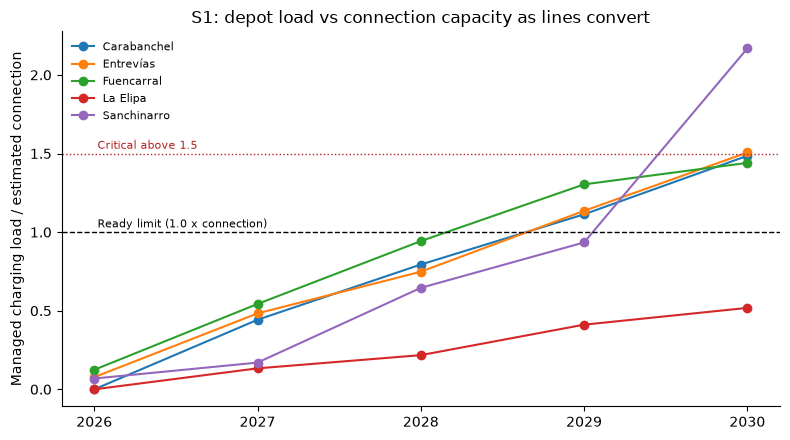

In [26]:
# ===== 14-1  Insight: when does each depot outgrow its connection? (S1 sequence) =====
import matplotlib.pyplot as plt          # if missing: pip install matplotlib (outside the notebook), then restart the kernel
YR = list(range(2026, 2031))
night = (f2.assign(night=f2.peak_buses * f2.energy_kwh_bus_day / 1000)
           .pivot_table(index='electrification_year', columns='depot_name', values='night', aggfunc='sum', fill_value=0)
           .reindex(YR, fill_value=0).cumsum())
load_mw = night / (FIXED['window_h'] * FIXED['eff'])                      # managed charging power of the lines converted so far
conn = f3.connection_mw_estimate.reindex(load_mw.columns)
ratio_ts = load_mw / conn
print('Managed load of converted lines / estimated connection, by year:')
print(ratio_ts.round(2).to_string())
cross = {d: next((y for y in YR if ratio_ts.loc[y, d] > 1), None) for d in load_mw.columns}
cross15 = {d: next((y for y in YR if ratio_ts.loc[y, d] > 1.5), None) for d in load_mw.columns}
print('\nFirst year the load exceeds the connection (ratio > 1):', cross)
print('First year it exceeds 1.5 x the connection (Critical):', cross15)

fig, ax = plt.subplots(figsize=(8, 4.5))
for d in load_mw.columns:
    if load_mw[d].max() > 0:
        ax.plot(YR, ratio_ts[d], marker='o', label=d)
ax.axhline(1.0, color='black', lw=1, ls='--'); ax.axhline(1.5, color='firebrick', lw=1, ls=':')
ax.text(2026.02, 1.03, 'Ready limit (1.0 x connection)', fontsize=8); ax.text(2026.02, 1.53, 'Critical above 1.5', fontsize=8, color='firebrick')
ax.set_xticks(YR); ax.set_ylabel('Managed charging load / estimated connection'); ax.set_title('S1: depot load vs connection capacity as lines convert')
ax.legend(frameon=False, fontsize=8); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(OUT_DIR / 'fig_depot_load_timeline.png', dpi=200); plt.show()

Depot diagnostic (standardised 100% BEV case):
             buses_assigned  night_energy_per_bus_kwh  peak_mw_managed  connection_mw_estimate  managed_to_connection  gap_mw_to_ready  managed_kw_per_bus  connection_kw_per_bus readiness_status
depot_name                                                                                                                                                                                        
Carabanchel             455                    205.68            14.85                   10.00                   1.49             4.85               32.65                  21.98          Upgrade
Fuencarral              477                    201.90            15.29                   10.61                   1.44             4.68               32.05                  22.25          Upgrade
La Elipa                287                    227.45            10.36                   20.00                   0.52             0.00               36.10                  6

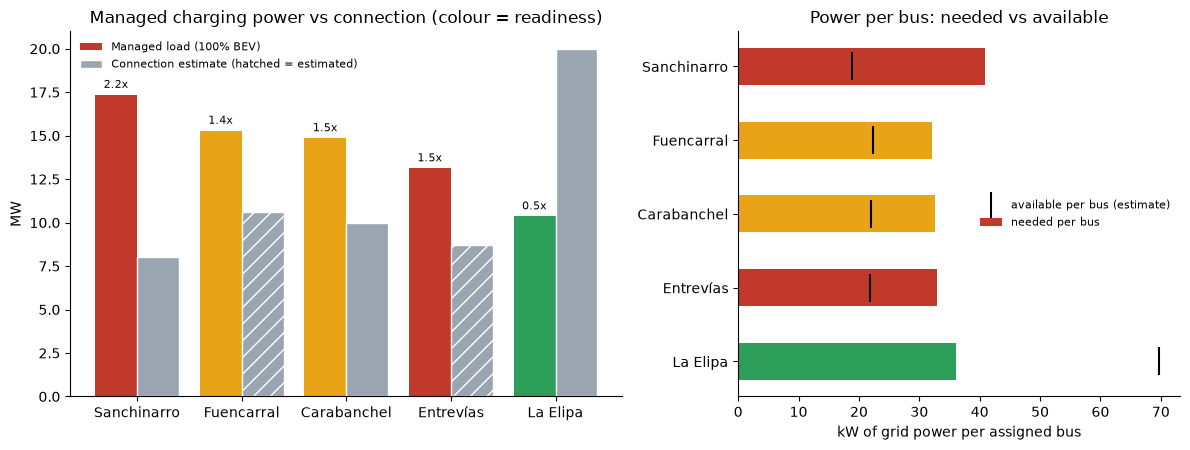

In [27]:
# ===== 10e-2  Grid diagnostic: where is the bottleneck and what drives it? =====
import matplotlib.pyplot as plt
READY_COL = {'Ready': '#2e9e5b', 'Upgrade': '#e8a317', 'Critical': '#c0392b'}      # brief: green / amber / red
d = f3.copy()
d['night_energy_per_bus_kwh'] = d.night_energy_mwh * 1000 / d.buses_assigned.replace(0, np.nan)
d['managed_kw_per_bus'] = d.peak_mw_managed * 1000 / d.buses_assigned.replace(0, np.nan)
d['connection_kw_per_bus'] = d.connection_mw_estimate * 1000 / d.buses_assigned.replace(0, np.nan)
d['gap_mw_to_ready'] = (d.peak_mw_managed - d.connection_mw_estimate).clip(lower=0)
d['gap_mw_to_upgrade_limit'] = (d.peak_mw_managed - 1.5 * d.connection_mw_estimate).clip(lower=0)
show = ['buses_assigned', 'night_energy_per_bus_kwh', 'peak_mw_managed', 'connection_mw_estimate', 'managed_to_connection',
        'gap_mw_to_ready', 'managed_kw_per_bus', 'connection_kw_per_bus', 'readiness_status']
print('Depot diagnostic (standardised 100% BEV case):'); print(d[show].round(2).to_string())
print(f"\nNetwork: managed {d.peak_mw_managed.sum():.1f} MW vs estimated connection {d.connection_mw_estimate.sum():.1f} MW "
      f"-> additional {d.gap_mw_to_ready.sum():.1f} MW needed for every depot to be Ready (case {ALLOC_CASE}, connection scenario {CONN_SCENARIO})")
print(f"Sanity check: managed MW x 7 h = {d.peak_mw_managed.sum()*FIXED['window_h']:.0f} MWh grid input per day "
      f"= {d.night_energy_mwh.sum()/FIXED['eff']:.0f} MWh (night energy / 0.90)")

# what drives each depot's load: line concentration, bus type, long lines
x = f2.assign(night=f2.peak_buses * f2.energy_kwh_bus_day / 1000)
rows = []
for dep, g in x.groupby('depot_name'):
    g = g.sort_values('night', ascending=False)
    rows.append([dep, len(g), g.night.sum(), 100 * g.night.head(10).sum() / g.night.sum(),
                 100 * g[g.km_per_bus_day > 0.8 * g.bus_type.map(LIMIT)].night.sum() / g.night.sum(),
                 100 * g[g.bus_type == 'Articulated'].night.sum() / g.night.sum(),
                 100 * g[g.charging_strategy != 'Depot'].night.sum() / g.night.sum()])
drv = pd.DataFrame(rows, columns=['depot', 'lines', 'night_mwh', 'top10_lines_%', 'lines_over_80%_of_range_%', 'articulated_%', 'opportunity_lines_%']).set_index('depot')
print('\nShare of each depot\'s night energy by line type:'); print(drv.round(1).to_string())

# what the Opportunity lines would change: half of their energy delivered at the terminals instead of the depot
opp_mwh = x[x.charging_strategy != 'Depot'].groupby('depot_name').night.sum()
print('\nNight energy of the Opportunity lines (MWh):', opp_mwh.round(1).to_dict(),
      f'| as % of the network night energy: {100 * opp_mwh.sum() / x.night.sum():.1f}%')

# sensitivity of managed power to the charging window (supplementary, the brief fixes 7 h)
win = pd.DataFrame({f'{h} h': d.night_energy_mwh / (h * FIXED['eff']) for h in (5, 6, 7, 8)})
print('\nSupplementary: managed MW if the real window were shorter or longer than 7 h:'); print(win.round(1).to_string())
print('Network total:', win.sum().round(1).to_dict())

# figure: managed load against the connection estimate, coloured by readiness
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1.25, 1]})
dd = d.loc[d.buses_assigned > 0].sort_values('peak_mw_managed', ascending=False)
pos = np.arange(len(dd))
ax[0].bar(pos - 0.2, dd.peak_mw_managed, 0.4, color=[READY_COL[s] for s in dd.readiness_status], label='Managed load (100% BEV)')
ax[0].bar(pos + 0.2, dd.connection_mw_estimate, 0.4, color='#9aa5b1', hatch=['' if e == 'Evidenced' else '//' for e in dd.connection_evidence], edgecolor='white', label='Connection estimate (hatched = estimated)')
for p, (_, r) in zip(pos, dd.iterrows()):
    ax[0].text(p - 0.2, r.peak_mw_managed + 0.4, f'{r.managed_to_connection:.1f}x', ha='center', fontsize=8)
ax[0].set_xticks(pos); ax[0].set_xticklabels(dd.index); ax[0].set_ylabel('MW'); ax[0].set_title('Managed charging power vs connection (colour = readiness)')
ax[0].legend(frameon=False, fontsize=8); ax[0].spines[['top', 'right']].set_visible(False)
ax[1].barh(dd.index, dd.managed_kw_per_bus, color=[READY_COL[s] for s in dd.readiness_status], height=0.5, label='needed per bus')
ax[1].scatter(dd.connection_kw_per_bus, dd.index, color='black', zorder=3, marker='|', s=400, label='available per bus (estimate)')
ax[1].set_xlabel('kW of grid power per assigned bus'); ax[1].set_title('Power per bus: needed vs available'); ax[1].invert_yaxis()
ax[1].legend(frameon=False, fontsize=8); ax[1].spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(OUT_DIR / 'fig_depot_diagnostic.png', dpi=200); plt.show()

100% BEV load by depot: before the reopening (B) vs after it (A):
             buses_B  buses_A   MW_B   MW_A  conn_MW  ratio_B  ratio_A  status_B  status_A
depot_name                                                                                
Carabanchel      455      455  14.85  14.85    10.00     1.49     1.49   Upgrade   Upgrade
Fuencarral       764      477  25.65  15.29    10.61     2.42     1.44  Critical   Upgrade
La Elipa           0      287   0.00  10.36    20.00     0.00     0.52     Ready     Ready
Entrevías        399      399  13.12  13.12     8.71     1.51     1.51  Critical  Critical
Sanchinarro      424      424  17.35  17.35     8.00     2.17     2.17  Critical  Critical

Gap to Ready (MW, sum over depots): B 33.7 | A 23.3  (total need unchanged: 71.0 MW)

Managed load of converted lines / connection, by year (allocation switches in 2029 ):
depot_name  Carabanchel  Fuencarral  La Elipa  Entrevías  Sanchinarro
2026               0.00        0.12      0.00       0.

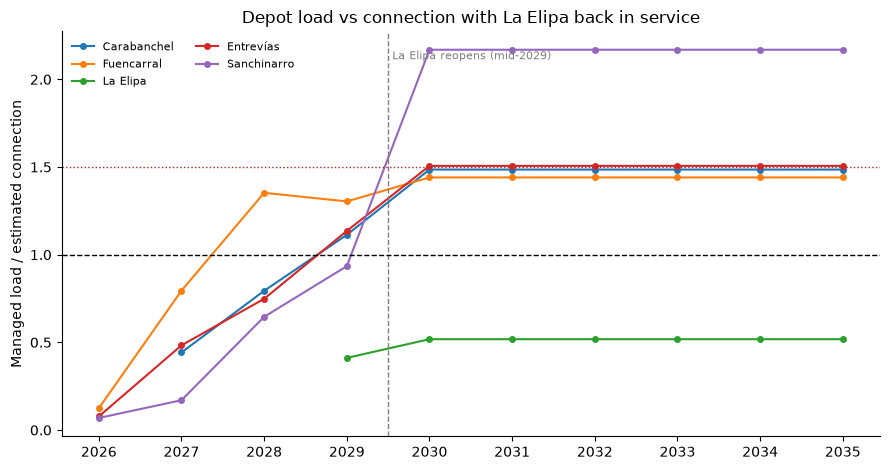

In [28]:
# ===== 10e-3  La Elipa reopening (mid-2029): depot allocation that changes over time =====
import matplotlib.pyplot as plt
LA_ELIPA_REOPEN = 2029.5          # reopens in mid-2029 (stated by the team; source to cite in the report)
OPEN_FROM_YEAR = int(np.floor(LA_ELIPA_REOPEN))       # first year-END snapshot with La Elipa open: 2029 (reopening on 1 July)
YR = list(range(2026, 2036))

def depot_in(year):
    """Depot of each line at the end of `year`: case B (La Elipa lines at Fuencarral / Entrevías) before the reopening, case A after it."""
    return f2.depot_A if year >= OPEN_FROM_YEAR else f2.depot_B

# 1) the two allocations side by side (100% BEV case, base connection)
gB, gA = build_file3(f2, 'depot_B'), build_file3(f2, 'depot_A')
cmp_ = pd.DataFrame({'buses_B': gB.buses_assigned, 'buses_A': gA.buses_assigned,
                     'MW_B': gB.peak_mw_managed, 'MW_A': gA.peak_mw_managed, 'conn_MW': gA.connection_mw_estimate,
                     'ratio_B': gB.managed_to_connection, 'ratio_A': gA.managed_to_connection,
                     'status_B': gB.readiness_status, 'status_A': gA.readiness_status})
print('100% BEV load by depot: before the reopening (B) vs after it (A):'); print(cmp_.round(2).to_string())
print(f"\nGap to Ready (MW, sum over depots): B {(gB.peak_mw_managed - gB.connection_mw_estimate).clip(lower=0).sum():.1f} | "
      f"A {(gA.peak_mw_managed - gA.connection_mw_estimate).clip(lower=0).sum():.1f}  (total need unchanged: {gA.peak_mw_managed.sum():.1f} MW)")

# 2) load per depot by year for the File 2 conversion sequence, depot taken from the allocation valid in that year
rows = []
for y in YR:
    dep = depot_in(y)
    conv = f2.electrification_year <= y
    n = (f2.peak_buses * f2.energy_kwh_bus_day / 1000)[conv].groupby(dep[conv]).sum().reindex(DEPOTS.index).fillna(0)
    rows.append(n / (FIXED['window_h'] * FIXED['eff']))
load_t = pd.DataFrame(rows, index=YR)
conn_t = gA.connection_mw_estimate.reindex(load_t.columns)
ratio_t = load_t / conn_t
print('\nManaged load of converted lines / connection, by year (allocation switches in', OPEN_FROM_YEAR, '):'); print(ratio_t.round(2).to_string())
print('\nFirst year above 1.0 x connection:', {d: next((y for y in YR if ratio_t.loc[y, d] > 1), None) for d in ratio_t.columns})
print('First year above 1.5 x connection:', {d: next((y for y in YR if ratio_t.loc[y, d] > 1.5), None) for d in ratio_t.columns})

# 2b) what if the reopening slips? (Fuencarral keeps the La Elipa lines until the new centre opens)
slip = {}
for open_y in (2029, 2030, 2031):
    r = {}
    for y in YR:
        dep = f2.depot_A if y >= open_y else f2.depot_B
        conv = f2.electrification_year <= y
        n = (f2.peak_buses * f2.energy_kwh_bus_day / 1000)[conv].groupby(dep[conv]).sum().reindex(DEPOTS.index).fillna(0)
        r[y] = (n / (FIXED['window_h'] * FIXED['eff']) / conn_t)['Fuencarral']
    slip[f'opens {open_y}'] = pd.Series(r)
print('\nFuencarral load / connection by year if La Elipa opens at the end of 2029, 2030 or 2031 (> 1.5 = Critical):')
print(pd.DataFrame(slip).round(2).T.to_string())
print('New centre: 318 buses (20 articulated), 318 inverted pantographs, substation up to 20 MW, up to 32 months from contract signing (construible.es, 2 Oct 2026).')

# 3) lines that change depot at the reopening, and the electrification year they carry
mv = f2[f2.depot_A != f2.depot_B]
print(f"\n{len(mv)} lines return to La Elipa ({int(mv.peak_buses.sum())} buses). Of them already converted before the reopening: "
      f"{int((mv.electrification_year < OPEN_FROM_YEAR).sum())} lines ({int(mv.loc[mv.electrification_year < OPEN_FROM_YEAR, 'peak_buses'].sum())} buses) "
      f"- those buses move from the interim depot to La Elipa, which therefore needs charging points when it reopens.")
print(mv.groupby(['depot_B', 'electrification_year']).peak_buses.sum().unstack(fill_value=0).to_string())

fig, ax = plt.subplots(figsize=(9, 4.8))
for d in ratio_t.columns:
    s = ratio_t[d].where(load_t[d] > 0)
    ax.plot(YR, s, marker='o', ms=4, label=d)
ax.axvline(LA_ELIPA_REOPEN, color='grey', ls='--', lw=1); ax.text(LA_ELIPA_REOPEN + 0.05, ax.get_ylim()[1] * 0.93, 'La Elipa reopens (mid-2029)', fontsize=8, color='grey')
ax.axhline(1.0, color='black', lw=1, ls='--'); ax.axhline(1.5, color='firebrick', lw=1, ls=':')
ax.set_xticks(YR); ax.set_ylabel('Managed load / estimated connection'); ax.set_title('Depot load vs connection with La Elipa back in service')
ax.legend(frameon=False, fontsize=8, ncol=2); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(OUT_DIR / 'fig_depot_load_la_elipa.png', dpi=200); plt.show()

## 11. Assumptions register (V / D / P / A)
Printed so that it can be read in the saved notebook. The final report carries the full version, with links, in an annex.

In [92]:
reg = pd.DataFrame([
 ['A01', 'Reference date', REFERENCE_DATE + ' (Tuesday)', 'D', 'GTFS valid from 2026-11-06; not a holiday; trip count similar to nearby weekdays', 'Timetable, km', 'Nearby weekdays compared (Section 3). Strikes cannot be checked for a future date: re-check.'],
 ['A02', 'GTFS trips are individual trips; frequencies.txt ignored', '38k trips, all with stop_times; 1.1M implied runs if expanded', 'D', 'Sections 3 and 7', 'Daily km', 'Expanding frequencies is shown to be implausible.'],
 ['A03', 'Trip length', 'shape_dist_traveled (m); fallback shape geometry', 'D', 'Median ratio to haversine shape length close to 1', 'Daily km', 'Two methods agree.'],
 ['A04', 'In-service km only', 'no deadheading', 'A', 'GTFS contains no depot runs', 'Energy and range', 'Discussed in the report as a limitation.'],
 ['A05', 'peak_buses source and day', f'EMT supply data, proxy day {SUPPLY_PROXY_DATE}', 'P', 'Supply ends 2026-08-31, GTFS starts 2026-11-06', 'Buses, km per bus', f'High/low days {list(SUPPLY_SENS_DATES.values())}: Section 9.'],
 ['A06', 'Line identifier mapping', 'label from stops and history tables, longest label', 'D', 'Section 6', 'Joins', 'Match rate printed in Section 6.'],
 ['A07', 'Internal line 832 = SE832', 'manual override', 'P', 'Only GTFS special service left unmatched; history lists 832 as a special service', 'One line', 'Single line, small impact.'],
 ['A08', 'peak_buses for lines without supply record', 'ceil(km / median km per bus), at least 1', 'P', 'Lines: ' + ', '.join(f2.loc[f2.peak_buses_source == 'proxy', 'line_id']), 'Two lines', 'Negligible: 2 of ~2,040 buses.'],
 ['A09', 'Fleet baseline 31 Dec 2025', f'{FLEET_TOTAL} = {N_BEV} BEV + {N_H2} H2 + {N_CNG} CNG', 'D / V', 'Fleet history, one row per vehicle; matches the city service charter (2,210) and EMT (452 electric)', 'File 1, File 4', 'Alternatives 2,215 and 2,239 documented (Section 5).'],
 ['A10', 'Articulated fleet', f'{n_art} buses (type code 2)', 'D', 'Capacity about 118; equals the two "-ART" models', 'Bus type', 'No articulated electric bus at baseline.'],
 ['A11', 'Hydrogen buses and minibuses counted as Standard', '10 H2 (74 seats), 13 minibuses (41 seats)', 'A', 'Brief has only two bus types', 'Energy factors', 'Small.'],
 ['A12', 'Bus type per line', 'most passengers per peak bus, regular lines with >= ' + str(MIN_BUSES_ART) + ' peak buses, until articulated share is met', 'P / A', 'Nothing links vehicles to lines; line 34 is a validation point', 'Energy, strategy', 'To test: alternative ranking (for example by peak buses).'],
 ['A13', 'Opportunity limit', f'{OPP_MAX} x effective range', 'A', 'Midday top-up at terminals is physically credible up to about twice the range', 'Strategy', 'Tested at 1.5x, 2.0x, 2.5x (Section 9).'],
 ['A14', 'Vehicle-block proxy (stress test)', 'median buses over active time bands', 'D', 'Brief, rule 2', 'Lines over range', f'{int(f2.over_range.sum())} lines (peak rule) vs {int(alt.over_alt.sum())} (median rule).'],
 ['A15', 'Depot assignment', 'latest depot code in the history table', 'P', f'{int((f2.evid_year <= 2019).sum())} of {int(f2.evid_year.notna().sum())} lines have a record from 2019 or earlier', 'Depot totals', 'Case A vs case B (Section 10).'],
 ['A16', 'Depot code names', '62825 Fuencarral, 62835 Carabanchel, 62845 La Elipa, 62865 Entrevías, 62875 Sanchinarro', 'P', 'Terminal geography; March 2022 moves match the press', 'Naming', 'To confirm: geocode the depot addresses from the brief.'],
 ['A17', 'La Elipa closed provisionally (March 2022)', 'day lines to Fuencarral; night lines and Cañada Real to Entrevías', 'V / P', 'City press (diario.madrid.es); history table shows the six moves to Entrevías only', 'Fuencarral load', 'Case A shown as sensitivity.'],
 ['A18', 'Fixed parameters', 'energy 1.30 / 1.85 kWh/km; range 300 / 240 km; 100 kW; 7 h; 90%', 'V', 'Brief, Section 4.5', 'All energy', 'Alternatives only as supplementary.'],
 ['A20', 'CNG CO2 factor', f'{CNG_CO2_KG_PER_KWH_PCS} kg CO2/kWh PCS x {CNG_PCS_KWH_PER_KG} kWh/kg = {CNG_CO2_KG_PER_KWH_PCS*CNG_PCS_KWH_PER_KG:.2f} kg CO2/kg', 'V / A', 'MITECO Registro de huella (natural gas); heating value is our assumption', 'CO2 avoided', 'Tested at 14.0 and 15.4 kWh/kg (Section 10b). To verify: MITECO vehicle-fuel factor.'],
 ['A21', 'Electricity CO2 factor', f'{ELEC_TOTAL_MT_CO2EQ} Mt / {ELEC_GENERATION_TWH} TWh = {ELEC_TOTAL_MT_CO2EQ/ELEC_GENERATION_TWH:.3f} kg/kWh', 'D / P', 'Red Eléctrica, Informe del Sistema Eléctrico 2025; generation total derived from the renewable share', 'CO2 avoided', 'Replace with the official REE annual factor; tested at 0.19 and 0.05.'],
 ['A22', 'Priority score and S1 ramp', f'weight {W_IMPACT} CO2 / {1-W_IMPACT} headroom; Depot lines first; ramp {list(S1_RAMP.values())}', 'A', 'Multi-criteria logic; rank and year consistent by construction', 'Rank, year', 'Equal 20% steps compared in Section 10b.'],
 ['A23', 'Depot addresses and coordinates', 'official addresses (EMT 2025 recruitment syllabus); coordinates from OpenStreetMap Nominatim', 'D / P', 'Addresses are official; Sanchinarro and Entrevías have a second wording in EMT\'s property inventory', 'File 3 map', 'Check every point on a map. Las Tablas excluded: no opening date, no power figure.'],
 ['A24', 'Depot connection MW', f'Carabanchel 10 MVA (evidenced); others = Carabanchel MW per 2021 bus x 2021 buses, scenario {CONN_SCENARIO}', 'V / A', 'EMT / Ayuntamiento: two transformation centres, 10 MVA combined (installed, not a contract)', 'Readiness', 'Low / base / high = 0.5 / 1.0 / 1.5 (Section 10c); likely optimistic for less electrified depots.'],
 ['A25', 'La Elipa row and depot allocation', f'Files 2 and 3 use the end state (case A): La Elipa takes its lines back; case B is the interim until mid-2029', 'A', 'New centre for 318 buses awarded 30/09/2026, up to 32 months (construible.es, Diario Madrid); reopening mid-2029 from the team', 'File 2 depot_name, File 3 La Elipa row', f'conversion_year of La Elipa = max electrification_year of its lines. Interim loads: section 10e-3. Placeholder {EMPTY_DEPOT_YEAR} only applies if a depot has no lines.'],
 ['A26', 'La Elipa new centre', '318 buses (20 articulated), 318 pantographs, substation up to 20 MW, reopening mid-2029 (<= 32 months from signing)', 'V / D', 'construible.es 2 Oct 2026 (award OHLA-Seranco); reopening date from the team', 'La Elipa connection, allocation from 2029', '20 MW is the substation ceiling, not a confirmed contracted connection: confirm with EMT. Allocation switches from case B to case A at the end of 2029 (LA_ELIPA_REOPEN).'],
 ['A27', 'Depot power data from EMT / city sources', 'Sanchinarro: 8 MW primary + 5 MW backup (not counted), 114 pantographs, contract 12.58 M EUR excl. VAT, CEF 4.69 M EUR; Fuencarral: smart charging for 20 buses, up to 180 kW per point, > 4 M EUR; Carabanchel: 40 chargers x 360 kW, 118 pantographs in phase III, 260 points now, 320 planned; 2027 budget: 65 buses for 34.3 M EUR, about 600 zero-emission buses', 'V', 'madrid360.es Carabanchel (22/03/2024: 40 chargers up to 360 kW each = 14.4 MW nameplate, 118 pantographs, two transformers 10 MVA); diario.madrid.es: Sanchinarro 114 pantografos (29/03/2026); Carabanchel phase III (2024) and 2023 article; Fuencarral smart charging (10/08/2022); ecoticias.com 2 Nov 2026 (EMT budget); construible.es 2 Oct 2026 (La Elipa)', 'Connection MW of Sanchinarro (8 MW) and La Elipa (20 MW)', 'OPEN: Carabanchel connection. Phase III states 10 MVA (two transformation centres); a 2023 article states a 20 MVA distribution centre and a 5 MVA transformer centre. If the depot total is 25 MVA or more, Carabanchel is Ready and the proxy for the other depots rises. Confirm with EMT.'],

 ['A28', 'Carabanchel contracted supply', '8 MW contracted with Iberdrola (Feb 2023, before phase III); installed transformers: 20 MVA distribution centre + 5 MVA transformer centre (2023) and 10 MVA in phase III (2024)', 'V', 'NotebookLM extraction (El Espanol 23/02/2023; esmartcity 27/02/2023; Madrid 360 22/03/2024) - verify quotes in the originals', 'Carabanchel connection', 'Model keeps 10 MW. Contracted power may be 8 MW (ratio 1.86, Critical) to 10 MW (1.49, Upgrade); the 25-35 MVA transformer totals are installed capacity, not contract.'],
 ['A29', 'Fuencarral to Las Tablas', 'POLIS (Dec 2023): Fuencarral to move to a new 100% electric depot at Las Tablas, plans for 500 pantographs', 'P', 'NotebookLM extraction of POLIS Network, not yet verified', 'Depot list, Fuencarral load', 'OPEN: date, scope (all of Fuencarral?) and whether Las Tablas is a sixth depot for File 3. Ask the mentor.'],
 ['A30', 'Hydrogen buses on line 73', '10 H2 buses run line 73 (Entrevias), but File 2 has line 73 (8 peak buses) at Sanchinarro, converting in 2030', 'P', 'NotebookLM extraction (EMT blog 19/12/2024)', 'File 2 line 73, Entrevias load', 'CHECK: exclude line 73 from the battery conversion or document why it stays.'],
 ['A31', 'Charging window and tariff', 'Off-peak tariff P3 00:00-08:00 on weekdays and all weekend; smart charging saves about 30% of energy cost', 'V', 'NotebookLM extraction (Iberdrola / Repsol tariff pages; Madrid 360 2025)', 'Window of 7 h', 'The brief window of 7 h sits inside the 8 h valley; the 8 h case (62 MW) is the upper bound.'],
 ['A32', 'Measured e-bus consumption', 'Irizar 12 m about 1.20 kWh/km (430 kWh for 350 km); EMT 2021 report 1.55-1.91 kWh/km; Solaris test 1.49', 'P', 'NotebookLM extraction (El Espanol 2023; EMT 2021 management report)', 'Energy per bus', 'Brief fixes 1.30 / 1.85 kWh/km. Use measured values as a sensitivity only: +20% to +45% energy raises every depot load by the same share.'], ['A19', 'Active vs physical fleet', f'{int(f2.peak_buses.sum())} peak buses vs {FLEET_TOTAL} fleet', 'D', 'Gap = reserve and maintenance fleet; not inserted into buses_assigned', 'Depot fleet', f'Implied reserve {100*(1-f2.peak_buses.sum()/FLEET_TOTAL):.1f}% of the fleet.'],

 ['A33', 'Infrastructure cost per charging point', 'Base 95,800 EUR (Carabanchel phase III: 11.3 M EUR for 118 pantographs); low 35,300 (11.3 M / 320, earlier assumption); high 110,400 (Sanchinarro: 12.58 M EUR for 114 pantographs); La Elipa full depot rebuild 352,600 per berth (112.1 M / 318) is not comparable', 'V / D', 'Madrid 360 / EMT 2024; EMT press release 29/03/2026; Diario Madrid 30/09/2026 (NotebookLM extraction)', 'Infrastructure capex in File 4', 'Corrects the earlier denominator (320 points planned for the whole depot). Grid upgrade cost per MW: NOT FOUND.'],
 ['A34', 'Official fleet milestones', 'E-buses: 180 (Feb 2023), 276 (Mar 2024), 432 (Mar 2025), 452 (Dec 2025); EMT target above 25% electric in 2027; about 600 zero-emission after the 2027 purchase', 'V', 'El Espanol 2023; Madrid 360 2024; Diario Madrid 2025; OKdiario 30/03/2026 (NotebookLM extraction)', 'S0 pace and 2027 level', 'S0 reaches 642 e-buses in 2027 (29.5%), above the EMT statement; CO2 factors: NOT FOUND in sources.'],], columns=['id', 'variable', 'value', 'class', 'evidence', 'impact', 'sensitivity / note'])
reg = reg.sort_values('id').reset_index(drop=True)
print(reg.to_string(index=False))

 id                                                 variable                                                                                                                                                                                                                                                                                                                                                                 value class                                                                                                                                                                                                                                                                                                                                                           evidence                                                   impact                                                                                                                                                                    

## 12. Regression checks
Reference values from the validated run of the working notebook. If any line says FAIL, the cleaned notebook no longer reproduces the earlier results and the cause must be found before building Files 3 and 4 on top of it.

In [93]:
def check(name, got, expected):
    ok = (got == expected) if not isinstance(expected, float) else abs(got - expected) < 1e-6
    print(('PASS ' if ok else 'FAIL ') + f'{name}: got {got!r}, expected {expected!r}')

depotA = f2.groupby('depot_A').peak_buses.sum().to_dict()
check('Lines in File 2', len(f2), 234)
check('GTFS trips on the reference date', len(t_ref), 38396)
check('Total daily km (rounded)', int(round(f2.daily_km.sum())), 339220)
check('Total peak buses (incl. 2 proxied lines)', int(f2.peak_buses.sum()), 2042)
check('Fleet at 31 Dec 2025', FLEET_TOTAL, 2210)
check('BEV / H2 / CNG', (N_BEV, N_H2, N_CNG), (452, 10, 1748))
check('Unadjusted S0 pace (ZE buses per year)', float(S0_PACE_UNADJUSTED), 77.0)
check('Articulated lines flagged', sorted(art_codes, key=int), ['34', '58', '61', '103', '113', '136'])
check('Lines over range, peak-bus rule', int(f2.over_range.sum()), 6)
check('Lines over range, median-bus rule', int(alt.over_alt.sum()), 23)
check('Charging strategy', f2.charging_strategy.value_counts().to_dict(), {'Depot': 228, 'Opportunity': 6})
check('Peak buses per depot, case A', depotA,
      {'Carabanchel': 455, 'Entrevías': 399, 'Fuencarral': 477, 'La Elipa': 287, 'Sanchinarro': 424})
check('Fuencarral peak buses, case B', int(f2.groupby('depot_B').peak_buses.sum()['Fuencarral']), 764)
check('Lines whose depot evidence is from 2019 or earlier', int((f2.evid_year <= 2019).sum()), 167)

PASS Lines in File 2: got 234, expected 234
PASS GTFS trips on the reference date: got 38396, expected 38396
PASS Total daily km (rounded): got 339220, expected 339220
PASS Total peak buses (incl. 2 proxied lines): got 2042, expected 2042
PASS Fleet at 31 Dec 2025: got 2210, expected 2210
PASS BEV / H2 / CNG: got (452, 10, 1748), expected (452, 10, 1748)
PASS Unadjusted S0 pace (ZE buses per year): got 77.0, expected 77.0
PASS Articulated lines flagged: got ['34', '58', '61', '103', '113', '136'], expected ['34', '58', '61', '103', '113', '136']
PASS Lines over range, peak-bus rule: got 6, expected 6
PASS Lines over range, median-bus rule: got 23, expected 23
PASS Charging strategy: got {'Depot': 228, 'Opportunity': 6}, expected {'Depot': 228, 'Opportunity': 6}
PASS Peak buses per depot, case A: got {'Carabanchel': 455, 'Entrevías': 399, 'Fuencarral': 477, 'La Elipa': 287, 'Sanchinarro': 424}, expected {'Carabanchel': 455, 'Entrevías': 399, 'Fuencarral': 477, 'La Elipa': 287, 'Sanchina

## 13. Next steps (not in this notebook yet)
* **File 2:** done in Section 10b; before the final run, verify the two emission factors against the official sources.
* **File 3:** done in Section 10c; remaining: check the five coordinates on a map and confirm the La Elipa treatment with a mentor.
* **File 4:** S0 adjusted pace (tenders and contracted deliveries) and S1 (100% by 2030), with capex split by bus, charger, depot works and grid.
* **File 1:** benchmark cities (teammates), plus the Madrid row from this notebook.
* **Final cell of the submitted notebook:** read File_1 to File_4 back as saved (`dtype=str` for `line_id` so that `001` and `002` keep their zeros) and print the structure, the first 10 rows and the cross-file checks of rule 3.